# Prototype Comparison Based on Key Metrics

**Objective**  
Compare Flow A (no button) and Flow B (with button) across key evaluation metrics and formulate recommendations on which variant to advance to the production A/B test.

**Agenda:**
1. Setup and Data Ingestion
2. Target Feature Extraction
3. Primary Metric: Future Discount Noticeability*
4. Current and Joint Discount Noticeability
5. Future-Discount Comprehension Analysis
6. Offer Appeal
7. Conclusion

_* Future-discount noticeability is the primary comparison. The remaining tests provide diagnostic or exploratory context_

###  1. Setup and Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy import stats
import pingouin as pg
import statsmodels.stats.proportion as smprop
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar

In [2]:
# display settings for high-dimensional dataset
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 50)

In [3]:
# Load the dataset. Low_memory = False handles mixed types across columns
DATA_PATH = '../data/P1_FTD_cleaned_sample.csv'
df = pd.read_csv(DATA_PATH, low_memory = False)
print(f"Cleaned dataset loaded: {df.shape[0]} sessions, {df.shape[1]} columns")

Cleaned dataset loaded: 197 sessions, 175 columns


### 2. Target Feature Extraction

Further analysis focuses on the following target dimensions and survey variables:

**Primary Metric: Discount Noticeability**
- **Future Discount Noticeability (Retention Hook):**  
  Multi-select prompt: `'Q18. Did you notice any of the following additional details during the deposit process? Select all that apply. A discount was promised for future payments'`

**Diagnostic Metric: Current Discount Noticeability**
- **Applied Discount Noticeability (Current):**  
  Multi-select prompt: `'Q14. Did you notice any of the following during the deposit process? Select all that apply. A discount was applied'`

**Deep Dive: Comprehension of Repeat-Use Rules**
- **Payment Method Attribution.** Did users link the discount specifically to the payment method?  
  Single-select: `'Q22. How do you think the future discount will be given? Answer'`  
  *Target answer:* `'The discount will be given only if the same payment method is used'`
- **Time Constraint Awareness.** Did users recognize the 7-day redemption window?  
  Single-select: `'Q20. To which payments will this future discount be applied? Answer'`  
  *Target answer:* `'It will apply only if a payment is made within a specific period'`  
  Open-ended numeric: `'Q21. Within how many days should the next payment be made for the discount to apply? (Please enter the number of the days) Answer'`  
  *Target answer:* `7` (answers 1-7 days are accepted as valid retention window awareness, since a shorter perceived deadline maintains urgency, whereas values `> 7 days` miss the offer condition).
- **Discount Magnitude Recall.** Did users recall the exact incentive size (1%)?  
  Open-ended numeric: `'Q19. You noticed that a discount was promised for future payments. What was the amount of the discount promised? (Please specify the amount in %) Answer'`  
  *Target answer:* `1` or `1%`

**Diagnostic Evaluation: Offer Appeal**
- **Declared Intent to Switch Payment Method:**  
  Single-select: `'Q28. So, a 1% discount was applied to your current deposit, and a 1% discount was also promised on future deposits if they are made within 7 days using the same payment method. If you noticed this, would you make your next deposit using this payment method instead of your usual one? Answer'`  
  *Target answers:* `'Definitely yes, I would switch to this payment method'` / `'Probably yes, I would consider using this payment method'`
- **Declared Willingness to Deposit Within 7 Days:**  
  Single-select: `'Q30. Would you make a special effort to make your next deposit within 7 days to receive this 1% discount? Answer'`  
  *Target answer:* `'Yes'`
- **Historical Responsiveness to Time-Limited Offers (benchmark):**  
  Single-select: `'Q32. Think back to the last time an online investment, crypto, or trading platform offered you a limited-time bonus or discount if you acted within a certain time. Did you do it in time to get the bonus/discount? Answer'`  
  *Target answer:* `'Yes, I did it in time to get the bonus/discount'`

In [4]:
#function to extract col names using prefix ans substring 
def col_extractor (prefix: str = '', substring: str = ''):
    match = [c for c in df.columns if c.lower().startswith (prefix.lower()) and substring.lower() in c.lower()]
    if len (match) > 1:
        raise ValueError (f'Multiple matches for {prefix} and {substring}: {match}')
    elif not match:
        raise KeyError (f'Nothing found for {prefix} and {substring}')
    return match[0]


#map short feature name  -> (prefix, substring)
FEATURE_SCHEMA = {
    #Primary Metric: Discount Noticeability*
    "current_discount_noticed": ("Q14.", "A discount was applied"),
    "future_discount_noticed": ("Q18.", "A discount was promised for future payments"),

    #Deep Dive: Comprehension of Repeat-Use Rules
    "method_attribution": ("Q22.", ""),
    "time_constraint_aware": ("Q20.", ""),
    "time_constraint_days": ("Q21.", ""),
    "discount_magnitude_recalled": ("Q19.", "(Please specify the amount in %) Answer"),

    #Diagnostic Evaluation: Offer Appeal
    "intent_to_switch": ("Q28.", ""),
    "willingness_to_deposit_7d": ("Q30.", ""),
    "historical_promo_usage": ("Q32.", ""),

    #technical cols
    "flow": ("flow", ""),
    "age": ("age", ""),
    "gender": ("Q3.", "gender"),
}

#building dict long feature name ->  short feature name
long_short_names_mapped = {col_extractor(prefix, substring): short_name for short_name, (prefix, substring) in FEATURE_SCHEMA.items()}

#print final mapping to double-check 
for key, value in long_short_names_mapped.items():
    print (key,"\n/", value, '/\n')

Q14. Did you notice any of the following during the deposit process?
Select all that apply. A discount was applied 
/ current_discount_noticed /

Q18. Did you notice any of the following additional details during the deposit process?
Select all that apply. A discount was promised for future payments 
/ future_discount_noticed /

Q22. How do you think the future discount will be given? Answer 
/ method_attribution /

Q20. To which payments will this future discount be applied? Answer 
/ time_constraint_aware /

Q21. Within how many days should the next payment be made for the discount to apply? (Please enter the number of the days) Answer 
/ time_constraint_days /

Q19. You noticed that a discount was promised for future payments. 
What was the amount of the discount promised? (Please specify the amount in %) Answer 
/ discount_magnitude_recalled /

Q28. So, a 1% discount was applied to your current deposit, and a 1% discount was also promised on future deposits if they are made within 

In [5]:
#create a dataset with selected cols only
df_extracted = df[list(long_short_names_mapped)].rename(columns = long_short_names_mapped)

print(f'rows {df_extracted.shape[0]}, columns {df_extracted.shape[1]}')
df_extracted.head(3)


rows 197, columns 12


,current_discount_noticed,future_discount_noticed,method_attribution,time_constraint_aware,time_constraint_days,discount_magnitude_recalled,intent_to_switch,willingness_to_deposit_7d,historical_promo_usage,flow,age,gender
0,A discount was applied,NaN,NaN,NaN,NaN,NaN,"Probably yes, I would consider using this paym...",No,"No, I didn’t do it in time",Flow A (no button),34,Male
1,A discount was applied,A discount was promised for future payments,The discount will be given by the website wher...,It will apply only if a payment is made within...,7 days,1%,"Probably yes, I would consider using this paym...",No,I’ve never been offered this kind of bonus/dis...,Flow A (no button),33,Female
2,A discount was applied,NaN,NaN,NaN,NaN,NaN,"Definitely yes, I would switch to this payment...",It’s hard to say,"Yes, I did it in time to get the bonus/discount",Flow A (no button),21,Male


In [6]:
#check number of non-missing answers and data type
df_extracted.info()

<class 'pandas.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   current_discount_noticed     100 non-null    str  
 1   future_discount_noticed      66 non-null     str  
 2   method_attribution           66 non-null     str  
 3   time_constraint_aware        66 non-null     str  
 4   time_constraint_days         24 non-null     str  
 5   discount_magnitude_recalled  66 non-null     str  
 6   intent_to_switch             197 non-null    str  
 7   willingness_to_deposit_7d    197 non-null    str  
 8   historical_promo_usage       197 non-null    str  
 9   flow                         197 non-null    str  
 10  age                          197 non-null    int64
 11  gender                       197 non-null    str  
dtypes: int64(1), str(11)
memory usage: 18.6 KB


The noticeability variables (`current_discount_noticed`, `future_discount_noticed`) contain the selected option text or a missing value. Notebook 01 confirmed that all retained respondents answered both multi-select questions, so a missing value here means that the discount option was not selected.

The future-discount comprehension variables (method_attribution, time_constraint_aware,  time_constraint_days, discount_magnitude_recalled) contain missing values because these questions were only shown to respondents who reported noticing the future discount.

The exact time-limit question (time_constraint_days) has fewer recorded answers than the other comprehension questions because it was shown only to those who reported noticing time constraint.

All remaining extracted variables have no missing values.

### 3. Primary Metric: Future Discount Noticeability

**Objective**  
Compare how often respondents in Flow A and Flow B noticed the future discount when prompted. Users need to notice the offer before it can encourage repeat use. 

**Analysis Plan:**  
   3.1. Future discount noticeability (`future_discount_noticed`)    
   3.2. Sensitivity analysis 

#### 3.1. Future discount noticeability (`future_discount_noticed`)

**Objective**  
Establish which flow is more effective at driving future-discount noticeability  

**Steps:**
- Compare respondent counts and percentages by flow, report the absolute difference
- Test whether the observed difference is statistically significant (two-sided two-proportion z-test at alpha = 0.05)
- Report group proportions and the estimated difference with 95% confidence intervals (Wilson and Newcombe methods)

In [7]:
#convert target cols to boolean indicators
df_extracted['future_discount_noticed'] = df_extracted['future_discount_noticed'].notna()
df_extracted['current_discount_noticed'] = df_extracted['current_discount_noticed'].notna()

In [8]:
#calculate counts and percentages for the key metric - future-discount noticeability 
future_dsc_noticed_counts = pd.crosstab(df_extracted['future_discount_noticed'], df_extracted['flow'] )

future_dsc_noticed_pct = future_dsc_noticed_counts.div(future_dsc_noticed_counts.sum(axis=0), axis = 'columns').mul(100)
future_dsc_noticed_pct['delta_pp'] = future_dsc_noticed_pct['Flow A (no button)'] - future_dsc_noticed_pct['Flow B (with button)']

print('Counts')
display(future_dsc_noticed_counts)

print('Percentages')
display(future_dsc_noticed_pct.round(2))

Counts


flow,Flow A (no button),Flow B (with button)
future_discount_noticed,,
False,56,75
True,43,23


Percentages


flow,Flow A (no button),Flow B (with button),delta_pp
future_discount_noticed,,,
False,56.57,76.53,-19.96
True,43.43,23.47,19.96


Future-discount noticeability is higher in Flow A than in Flow B (43.43% vs. 23.47%), an observed difference of 19.96 percentage points.

I use a two-sided **two-proportion z-test** at a significance level of alpha = 0.05 to assess whether noticeability rates differ between the flows.

- H0: The noticeability rates are equal (p_A = p_B).
- H1: The noticeability rates differ (p_A ≠ p_B).

The test assumptions are satisfied:
- The outcome is binary
- The samples are independent: each respondent tested only one flow. 

Additionally below I inspect if expected counts of both outcomes under the null hypothesis exceed 10 in each group, supporting the normal approximation

In [9]:
# сheck expected counts against the rule-of-thumb threshold of 10
#extract counts and sample sizes for the flows
future_dsc_flow_a_b = ['Flow A (no button)', 'Flow B (with button)']
future_dsc_noticed_counts_ztest = future_dsc_noticed_counts.loc[True, future_dsc_flow_a_b]
future_dsc_noticed_samples_ztest = future_dsc_noticed_counts.loc[:, future_dsc_flow_a_b].sum(axis=0)

#calculate pooled proportions
future_dsc_pooled_noticeability = (
    future_dsc_noticed_counts_ztest.sum() / future_dsc_noticed_samples_ztest.sum()
)

#calculate expected counts
future_dsc_exp_counts_for_ztest = pd.DataFrame({
    'noticed': future_dsc_noticed_samples_ztest * future_dsc_pooled_noticeability,
    'not_noticed': future_dsc_noticed_samples_ztest * (1.0 - future_dsc_pooled_noticeability)
})

display(future_dsc_exp_counts_for_ztest.round(2))

,noticed,not_noticed
flow,,
Flow A (no button),33.17,65.83
Flow B (with button),32.83,65.17


In [10]:
#run z-test for proportions
ALPHA = 0.05
future_dsc_z_stat, future_dsc_p_val = smprop.proportions_ztest(
    count = future_dsc_noticed_counts_ztest, 
    nobs = future_dsc_noticed_samples_ztest, 
    alternative='two-sided')

#print results
future_dsc_delta_pp = float(future_dsc_noticed_pct.loc[True, 'delta_pp'])
print (f'The observed difference between flows: {future_dsc_delta_pp:.2f} p.p.')
print (f'Z stat: {future_dsc_z_stat:.4f}')
print (f'P value: {future_dsc_p_val:.4f}')

if future_dsc_p_val<=ALPHA:
    print (f"Reject H0 at {ALPHA}: the noticeability rates differ significantly.")
    if future_dsc_delta_pp > 0:
        print ('Flow A demonstrates a higher observed future-discount noticeability compared to Flow B')
    else:
        print ('Flow B demonstrates a higher observed future-discount noticeability compared to Flow A')
else:
    print ('Do not reject H0: there is insufficient evidence of a difference in noticeability rates.')


The observed difference between flows: 19.96 p.p.
Z stat: 2.9684
P value: 0.0030
Reject H0 at 0.05: the noticeability rates differ significantly.
Flow A demonstrates a higher observed future-discount noticeability compared to Flow B


Next, I calculate 95% confidence intervals for each flow's noticeability rate using the Wilson method and for the difference between flows
(A − B) using the Newcombe method (it combines the two Wilson intervals).

These methods are chosen for their generally more reliable coverage compared with standard Wald intervals.

In [11]:
# Calculate 95% Wilson confidence intervals for each flow's noticeability rate
future_dsc_noticed_ci_low, future_dsc_noticed_ci_high = (smprop.proportion_confint(
                                                         count = future_dsc_noticed_counts_ztest,
                                                         nobs  = future_dsc_noticed_samples_ztest,
                                                         alpha = ALPHA, 
                                                         method='wilson')
                                                         )

# extract noticeability percentages for display
future_dsc_noticeability_pct = future_dsc_noticed_pct.loc[True, future_dsc_flow_a_b] #percantages to display

# Build the results table
future_dsc_noticed_ci_results = pd.DataFrame({
    'sample_size': future_dsc_noticed_samples_ztest,
    'noticed_count': future_dsc_noticed_counts_ztest,
    'noticeability_rate_pct': future_dsc_noticeability_pct,
    'ci_low_pct': future_dsc_noticed_ci_low*100,
    'ci_high_pct': future_dsc_noticed_ci_high*100
})

display(future_dsc_noticed_ci_results.round(2))

,sample_size,noticed_count,noticeability_rate_pct,ci_low_pct,ci_high_pct
flow,,,,,
Flow A (no button),99,43,43.43,34.10,53.26
Flow B (with button),98,23,23.47,16.18,32.76


In [12]:
# Calculate 95% Newcombe confidence intervals for the difference between flows (A − B)
future_dsc_delta_ci_low, future_dsc_delta_ci_high = (smprop.confint_proportions_2indep(
                                                         count1 = future_dsc_noticed_counts_ztest.loc['Flow A (no button)'],
                                                         count2 = future_dsc_noticed_counts_ztest.loc['Flow B (with button)'],
                                                         nobs1  = future_dsc_noticed_samples_ztest.loc['Flow A (no button)'],
                                                         nobs2  = future_dsc_noticed_samples_ztest.loc['Flow B (with button)'],
                                                         alpha = ALPHA, 
                                                         compare ='diff',
                                                         method='newcomb')
                                                         )


# print the results

print (f'Confidence intervals for the difference between flows (A vs B) are {future_dsc_delta_ci_low*100:.2f} p.p.-{future_dsc_delta_ci_high*100:.2f} p.p.')


Confidence intervals for the difference between flows (A vs B) are 6.79 p.p.-32.20 p.p.


In [13]:
#prepare results 
future_dsc_delta_pp = float(future_dsc_noticed_pct.loc[True, 'delta_pp'])

future_dsc_noticed_rate_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'noticeability_rate_pct']
future_dsc_noticed_ci_low_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'ci_low_pct']
future_dsc_noticed_ci_high_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'ci_high_pct']

future_dsc_noticed_rate_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'noticeability_rate_pct']
future_dsc_noticed_ci_low_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'ci_low_pct']
future_dsc_noticed_ci_high_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'ci_high_pct']


# print noticeability rates and confidence intervals
print (f"""Future-discount noticeability
Flow A (no button) - {future_dsc_noticed_rate_pct_flow_a:.2f}% (95% Wilson CI: {future_dsc_noticed_ci_low_pct_flow_a:.2f}% to {future_dsc_noticed_ci_high_pct_flow_a:.2f}%)
Flow B (with button) - {future_dsc_noticed_rate_pct_flow_b:.2f}% (95% Wilson CI: {future_dsc_noticed_ci_low_pct_flow_b:.2f}% to {future_dsc_noticed_ci_high_pct_flow_b:.2f}%)
""")

# print the estimated difference and its confidence interval
print (f'The observed difference between flows (A - B): {future_dsc_delta_pp:.2f} p.p. (95% Newcombe CI: {future_dsc_delta_ci_low*100:.2f} p.p. to {future_dsc_delta_ci_high*100:.2f} p.p.)')

# print the hypothesis test result
print ('Two-sided two-proportion z-test')
print (f'Z stat = {future_dsc_z_stat:.4f}; P value  = {future_dsc_p_val:.4f}')

if future_dsc_p_val<=ALPHA:
    print (f"Reject H0 at {ALPHA}: the noticeability rates differ significantly.")
    if future_dsc_delta_pp > 0:
        print ('Flow A demonstrates a higher observed future-discount noticeability compared to Flow B')
    else:
        print ('Flow B demonstrates a higher observed future-discount noticeability compared to Flow A')
else:
    print ('Do not reject H0: there is insufficient evidence of a difference in noticeability rates.')

Future-discount noticeability
Flow A (no button) - 43.43% (95% Wilson CI: 34.10% to 53.26%)
Flow B (with button) - 23.47% (95% Wilson CI: 16.18% to 32.76%)

The observed difference between flows (A - B): 19.96 p.p. (95% Newcombe CI: 6.79 p.p. to 32.20 p.p.)
Two-sided two-proportion z-test
Z stat = 2.9684; P value  = 0.0030
Reject H0 at 0.05: the noticeability rates differ significantly.
Flow A demonstrates a higher observed future-discount noticeability compared to Flow B


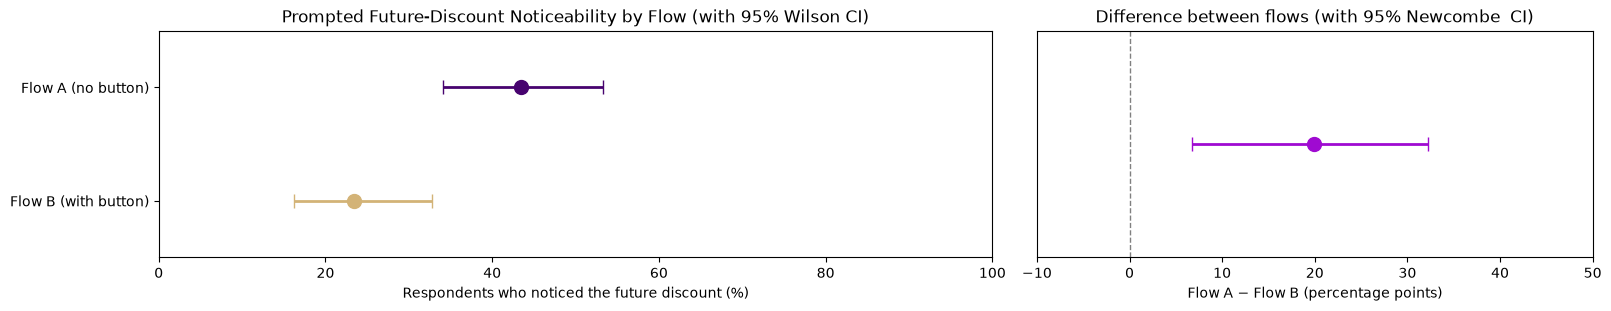

In [14]:
#мisualise the noticeability rates, the difference and their CIs
future_dsc_fig, future_dsc_axes = plt.subplots(ncols = 2, 
                                               figsize = (16,3),
                                               gridspec_kw = {'width_ratios': [1.5, 1]},
                                               layout = 'constrained')

#plot Flow A rate with its CI
future_dsc_axes[0].errorbar( x = future_dsc_noticed_rate_pct_flow_a,
                            y = 1, 
                            xerr = [[future_dsc_noticed_rate_pct_flow_a - future_dsc_noticed_ci_low_pct_flow_a],
                                    [future_dsc_noticed_ci_high_pct_flow_a - future_dsc_noticed_rate_pct_flow_a]],
                            fmt = 'o',
                            color = '#47036F',
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#plot Flow B rate with its CI
future_dsc_axes[0].errorbar( x = future_dsc_noticed_rate_pct_flow_b,
                            y = 2, 
                            xerr = [[future_dsc_noticed_rate_pct_flow_b - future_dsc_noticed_ci_low_pct_flow_b],
                                    [future_dsc_noticed_ci_high_pct_flow_b - future_dsc_noticed_rate_pct_flow_b]],
                            fmt = 'o',
                            color = "#D3B377",
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#rate plots settings
future_dsc_axes[0].set (
    title = 'Prompted Future-Discount Noticeability by Flow (with 95% Wilson CI)',
    xlabel='Respondents who noticed the future discount (%)',
    yticks=[1, 2],
    yticklabels=future_dsc_flow_a_b,
    xlim = (0, 100),
    ylim = (2.5, 0.5)
)

future_dsc_axes[1].errorbar( x = future_dsc_delta_pp,
                            y = 1, 
                            xerr = [[future_dsc_delta_pp - future_dsc_delta_ci_low*100],
                                    [future_dsc_delta_ci_high*100 - future_dsc_delta_pp]],
                            fmt = 'o',
                            color = "#9F0AD1",
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#difference plots settings
future_dsc_axes[1].set (
    title = 'Difference between flows (with 95% Newcombe  CI)',
    xlabel='Flow A − Flow B (percentage points)',
    yticks=[],
    xlim = (-10, 50),
    ylim = (0.5, 1.5)
)

# Mark no difference between flows
future_dsc_axes[1].axvline(
    x=0,
    color='gray',
    linestyle='--',
    linewidth=1
)

plt.show()

**Flow A (no button) demonstrates higher prompted future-discount noticeability than Flow B (with the “Accept and close” button): 43.43% vs 23.47%, a difference of +19.96 percentage points (95% Newcombe CI: +6.79 to +32.20 pp). The difference is statistically significant (two-sided two-proportion z-test, z = 2.97, p =  0.0030).**  
The confidence interval excludes zero but remains wide, indicating uncertainty about the size of Flow A's advantage.
*Note: This result does not establish an effect on actual repeat-payment behavior.*

The observed direction is opposite to the initial hypothesis that clicking "Accept and close" would encourage more deliberate processing
of the offer and improve recall. 
One possible explanation* is habitual pop-up dismissal ("cookie-banner blindness"): users may click "Accept and close" without reading the offer. In Flow B, this action also removes the reminder from the final payment confirmation screen, reducing opportunities to notice it.  
*This behavioral explanation remains a hypothesis. The comparison does not isolate habitual dismissal from the effect of fewer reminder exposures.* 

#### 3.2. Sensitivity analysis

**Objective**  
Test whether Flow A's advantage holds after accounting for age and gender differences.

**Rationale**  
Notebook 02 showed the largest observed differences in gender and age composition. Flow A has a higher share of men (+9.45 pp) and adults aged 55–65 (+8.00 pp), while Flow B has a higher share of adults aged 18–34 (+8.61 pp). We therefore check whether accounting for age and gender changes the comparison of future-discount noticeability.


**Steps:**
- Compare future-discount noticeability by flow within gender and age groups
- Fit an unadjusted logistic regression model (flow only) and an adjusted model (flow, age, gender)
- Calculate odds ratios, 95% confidence intervals, and p-values for both models
- Compare the unadjusted and adjusted odds ratios to assess how much accounting for age and gender changes the result

In [15]:
df_extracted.head(2)

,current_discount_noticed,future_discount_noticed,method_attribution,time_constraint_aware,time_constraint_days,discount_magnitude_recalled,intent_to_switch,willingness_to_deposit_7d,historical_promo_usage,flow,age,gender
0,True,False,NaN,NaN,NaN,NaN,"Probably yes, I would consider using this paym...",No,"No, I didn’t do it in time",Flow A (no button),34,Male
1,True,True,The discount will be given by the website wher...,It will apply only if a payment is made within...,7 days,1%,"Probably yes, I would consider using this paym...",No,I’ve never been offered this kind of bonus/dis...,Flow A (no button),33,Female


In [16]:
#сalculate future-discount noticeability by flow and gender
future_dsc_noticeability_gender_pct = pd.crosstab(
    index=df_extracted["future_discount_noticed"],
    columns=[
        df_extracted["flow"],
        df_extracted["gender"],
    ],
    normalize="columns",
).mul(100).round(0)

display(future_dsc_noticeability_gender_pct)

flow                    Flow A (no button)       Flow B (with button)      
gender                              Female  Male               Female  Male
future_discount_noticed                                                    
False                                 50.0  59.0                 71.0  79.0
True                                  50.0  41.0                 29.0  21.0

In [17]:
#create age groups
age_bins = [17, 34, 54, 65]
age_labels = ['18-34', '35-54', '55-65']
df_extracted['age_group'] = pd.cut (df_extracted['age'], bins = age_bins, right = True, labels = age_labels)

#сalculate future-discount noticeability by flow and age group
future_dsc_noticeability_age_group_pct = pd.crosstab(
    index=df_extracted["future_discount_noticed"],
    columns=[
        df_extracted["flow"],
        df_extracted["age_group"],
    ],
    normalize="columns",
).mul(100).round(0)

display(future_dsc_noticeability_age_group_pct)

flow                    Flow A (no button)             Flow B (with button)  \
age_group                            18-34 35-54 55-65                18-34   
future_discount_noticed                                                       
False                                 63.0  48.0  62.0                 80.0   
True                                  37.0  52.0  38.0                 20.0   

flow                                 
age_group               35-54 55-65  
future_discount_noticed              
False                    74.0  62.0  
True                     26.0  38.0

Overall conclusion
The subgroup comparisons suggest that differences in age and gender composition are unlikely to fully explain Flow A’s higher overall noticeability. Flow A had higher noticeability among both women and men, and in two of the three age groups.

Women also reported noticing the future discount more often than men in both flows. Since Flow B included a higher share of women, this difference in gender composition could improve its overall noticeability rate, making Flow A’s advantage appear smaller.

Next step
The tables compare the flows separately by gender and age group. Next, I use logistic regression to account for age and gender together and check whether this changes the estimated difference between flows.

In [18]:
#prepare a dataset to run logistic regressions
future_dsc_model_data = df_extracted[["future_discount_noticed", "flow", "age", "gender"]].copy()
future_dsc_model_data["future_discount_noticed"] = future_dsc_model_data["future_discount_noticed"].astype(int)

In [19]:

#spesify the unadjusted model and clearly set Flow B as the reference group to reflect previous A-B comparison
future_dsc_unadjusted_model = smf.logit(
    formula=( "future_discount_noticed ~ C(flow, Treatment(reference='Flow B (with button)'))" ),
    data=future_dsc_model_data
)

#estimate the parameters of the model
future_dsc_unadjusted_results = future_dsc_unadjusted_model.fit()

display(future_dsc_unadjusted_results.summary())

Optimization terminated successfully.
         Current function value: 0.615048
         Iterations 5


<class 'statsmodels.iolib.summary.Summary'>
"""
                              Logit Regression Results                             
===================================================================================
Dep. Variable:     future_discount_noticed   No. Observations:                  197
Model:                               Logit   Df Residuals:                      195
Method:                                MLE   Df Model:                            1
Date:                     Fri, 20 Nov 2026   Pseudo R-squ.:                 0.03549
Time:                             20:30:24   Log-Likelihood:                -121.16
converged:                            True   LL-Null:                       -125.62
Covariance Type:                 nonrobust   LLR p-value:                  0.002825
==============================================================================================================================================
                                                                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                     -1.1820      0.238     -4.959      0.000      -1.649      -0.715
C(flow, Treatment(reference='Flow B (with button)'))[T.Flow A (no button)]     0.9178      0.313      2.933      0.003       0.305       1.531
==============================================================================================================================================
"""

In [20]:
# сonvert the unadjusted model coefficient and confidence limits
# from the log-odds scale to the odds ratio scale

#save the name of the coefficient comparing Flow A with Flow B
FUTURE_DSC_FLOW_TERM = ("C(flow, Treatment(reference='Flow B (with button)'))[T.Flow A (no button)]")

#extract the difference in log-odds between Flow A and Flow B
future_dsc_unadj_log_odds_coef = future_dsc_unadjusted_results.params.loc[FUTURE_DSC_FLOW_TERM]
#exponentiate the coef to get the odds ratio for Flow A vs. Flow B
future_dsc_unadj_odds_ratio = np.exp(future_dsc_unadj_log_odds_coef)

#Extract the 95% CI to get the interval for the odds ratio
future_dsc_unadj_log_odds_ci = (future_dsc_unadjusted_results.conf_int(alpha=0.05).loc[FUTURE_DSC_FLOW_TERM])
#exponentiate CI borders from log-odds to the odds ratio scale
future_dsc_unadj_odds_ratio_ci = np.exp(future_dsc_unadj_log_odds_ci)

#extract the p-value for the Flow A vs. Flow B coefficient
future_dsc_unadj_p_value = (future_dsc_unadjusted_results.pvalues.loc[FUTURE_DSC_FLOW_TERM])

#build a one-row results table.
future_dsc_unadj_or_results = pd.DataFrame({
    "model": ["Unadjusted"],
    "comparison": ["Flow A vs. Flow B"],
    "odds_ratio": [future_dsc_unadj_odds_ratio],
    "ci_low": [future_dsc_unadj_odds_ratio_ci.loc[0]],
    "ci_high": [future_dsc_unadj_odds_ratio_ci.loc[1]],
    "p_value": [future_dsc_unadj_p_value],
})

# Round only the displayed values, keeping full precision in the table.
display(future_dsc_unadj_or_results.round(3))

,model,comparison,odds_ratio,ci_low,ci_high,p_value
0,Unadjusted,Flow A vs. Flow B,2.504,1.356,4.624,0.003


The unadjusted odds of noticing the future discount are 2.5 times as high in Flow A as in Flow B (95% CI: 1.36–4.62; p = 0.003).

Next, I fit a model that also accounts for age and gender and compare the results with the unadjusted model.

In [21]:
#spesify the adjusted model and clearly set Flow B as the reference group to reflect previous A-B comparison
#add age as a numeric predictor and gender with Female as the reference.
future_dsc_adjusted_model = smf.logit(
    formula=( "future_discount_noticed ~ "
    "C(flow,Treatment(reference='Flow B (with button)')) "
    "+ age "
    "+ C(gender, Treatment(reference='Female'))" 
    ),
    data=future_dsc_model_data
)

#estimate the parameters of the model
future_dsc_adjusted_results = future_dsc_adjusted_model.fit()

display(future_dsc_adjusted_results.summary())

Optimization terminated successfully.
         Current function value: 0.607402
         Iterations 5


<class 'statsmodels.iolib.summary.Summary'>
"""
                              Logit Regression Results                             
===================================================================================
Dep. Variable:     future_discount_noticed   No. Observations:                  197
Model:                               Logit   Df Residuals:                      193
Method:                                MLE   Df Model:                            3
Date:                     Fri, 20 Nov 2026   Pseudo R-squ.:                 0.04748
Time:                             20:30:24   Log-Likelihood:                -119.66
converged:                            True   LL-Null:                       -125.62
Covariance Type:                 nonrobust   LLR p-value:                  0.007627
==============================================================================================================================================
                                                                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                     -1.5744      0.591     -2.664      0.008      -2.733      -0.416
C(flow, Treatment(reference='Flow B (with button)'))[T.Flow A (no button)]     0.9328      0.319      2.923      0.003       0.307       1.558
C(gender, Treatment(reference='Female'))[T.Male]                              -0.4062      0.335     -1.211      0.226      -1.064       0.251
age                                                                            0.0173      0.014      1.278      0.201      -0.009       0.044
==============================================================================================================================================
"""

In [22]:
# сonvert the adjusted model coefficient and confidence limits
# from the log-odds scale to the odds ratio scale

#extract the difference in log-odds between Flow A and Flow B
future_dsc_adj_log_odds_coef = future_dsc_adjusted_results.params.loc[FUTURE_DSC_FLOW_TERM]
#exponentiate the coef to get the odds ratio for Flow A vs. Flow B
future_dsc_adj_odds_ratio = np.exp(future_dsc_adj_log_odds_coef)

#Extract the 95% CI to get the interval for the odds ratio
future_dsc_adj_log_odds_ci = (future_dsc_adjusted_results.conf_int(alpha=0.05).loc[FUTURE_DSC_FLOW_TERM])
#exponentiate CI borders from log-odds to the odds ratio scale
future_dsc_adj_odds_ratio_ci = np.exp(future_dsc_adj_log_odds_ci)

#extract the p-value for the Flow A vs. Flow B coefficient
future_dsc_adj_p_value = (future_dsc_adjusted_results.pvalues.loc[FUTURE_DSC_FLOW_TERM])

#build a one-row results table.
future_dsc_adj_or_results = pd.DataFrame({
    "model": ["Adjusted"],
    "comparison": ["Flow A vs. Flow B"],
    "odds_ratio": [future_dsc_adj_odds_ratio],
    "ci_low": [future_dsc_adj_odds_ratio_ci.loc[0]],
    "ci_high": [future_dsc_adj_odds_ratio_ci.loc[1]],
    "p_value": [future_dsc_adj_p_value],
})

# Round only the displayed values, keeping full precision in the table.
display(future_dsc_adj_or_results.round(3))

,model,comparison,odds_ratio,ci_low,ci_high,p_value
0,Adjusted,Flow A vs. Flow B,2.542,1.36,4.751,0.003


After accounting for age and gender, the odds of noticing the future discount are 2.54 times as high in Flow A as in Flow B (95% CI: 1.36–4.75; p = 0.003).

The adjusted estimate is close to the unadjusted estimate (OR = 2.5). Accounting for age and gender does not materially change the observed advantage of Flow A in this model.

**Future Discount Noticeability: Conclusion**

**Findings**
- In this prototype study, 43.43% of respondents in Flow A reported noticing the offer, compared with 23.47% in Flow B. This advantage of 19.96 pp is statistically significant (p = 0.003).
- The 95% confidence interval for this difference ranges from 6.79 to 32.20 pp. This supports a positive advantage for Flow A, although its exact size remains uncertain.

The samples differed somewhat in age and gender composition. However, the sensitivity analysis showed that the result remained similar after accounting for both characteristics, adding confidence that Flow A’s advantage is not simply due to differences in sample composition.

**Interpretation**  
Flow A is the stronger option for making the future discount noticeable

**Implications**  
These findings support taking Flow A forward as the preferred option for communicating the future discount. Whether this higher noticeability leads to more repeat payments still needs to be tested in production.

### 4. Current and Joint Discount Noticeability  

**Objective**  
Compare how often respondents in Flow A and Flow B noticed the current discount when prompted, and examine whether they noticed both the current and future discounts.

**Analysis Plan:**  
4.1. Current Discount Noticeability (`current_discount_noticed`)   
4.2. Joint Discount Noticeability

#### 4.1. Current Discount Noticeability (`current_discount_noticed`)

**Objective**  
Compare how often respondents in Flow A and Flow B noticed the discount applied to their current payment when prompted (Q14).

**Steps:**
- Compare respondent counts and percentages by flow, report the absolute difference
- Test whether the observed difference is statistically significant (two-sided two-proportion z-test at alpha = 0.05)
- Report the estimated difference with a 95% confidence interval (Newcombe method)


In [23]:
#calculate counts and percentages for current discount noticeability 
current_dsc_noticed_counts = pd.crosstab (df_extracted['current_discount_noticed'], df_extracted['flow'])

current_dsc_noticed_pct = current_dsc_noticed_counts.div(current_dsc_noticed_counts.sum(axis = 0), axis = "columns").mul(100)
current_dsc_noticed_pct['delta_pp'] = current_dsc_noticed_pct['Flow A (no button)'] - current_dsc_noticed_pct['Flow B (with button)']

print('Counts')
display(current_dsc_noticed_counts)

print('Percentages')
display(current_dsc_noticed_pct.round(2))

Counts


flow,Flow A (no button),Flow B (with button)
current_discount_noticed,,
False,44,53
True,55,45


Percentages


flow,Flow A (no button),Flow B (with button),delta_pp
current_discount_noticed,,,
False,44.44,54.08,-9.64
True,55.56,45.92,9.64


Current discount noticeability is higher in Flow A than in Flow B (55.56% vs. 45.92%), an observed difference of 9.64 percentage points.

I use a two-sided **two-proportion z-test** at a significance level of alpha = 0.05 to assess whether noticeability rates differ between the flows.

- H0: The noticeability rates are equal (p_A = p_B).
- H1: The noticeability rates differ (p_A ≠ p_B).

The test assumptions are satisfied:
- The outcome is binary
- The samples are independent: each respondent tested only one flow

Additionally below I inspect if expected counts of both outcomes under the null hypothesis exceed 10 in each group, supporting the normal approximation

In [24]:
# сheck expected counts against the rule-of-thumb threshold of 10
#extract counts and sample sizes for the flows
current_dsc_flow_a_b = ['Flow A (no button)', 'Flow B (with button)']
current_dsc_noticed_counts_ztest = current_dsc_noticed_counts.loc[True, current_dsc_flow_a_b]
current_dsc_noticed_samples_ztest = current_dsc_noticed_counts.loc[:, current_dsc_flow_a_b].sum(axis=0)

#calculate pooled proportions
current_dsc_pooled_noticeability = (
    current_dsc_noticed_counts_ztest.sum() / current_dsc_noticed_samples_ztest.sum()
)

#calculate expected counts
current_dsc_exp_counts_for_ztest = pd.DataFrame({
    'noticed': current_dsc_noticed_samples_ztest * current_dsc_pooled_noticeability,
    'not_noticed': current_dsc_noticed_samples_ztest * (1.0 - current_dsc_pooled_noticeability)
})

display(current_dsc_exp_counts_for_ztest.round(2))

,noticed,not_noticed
flow,,
Flow A (no button),50.25,48.75
Flow B (with button),49.75,48.25


In [25]:
#run z-test for proportions
ALPHA = 0.05
current_dsc_z_stat, current_dsc_p_val = smprop.proportions_ztest(
    count = current_dsc_noticed_counts_ztest, 
    nobs = current_dsc_noticed_samples_ztest, 
    alternative='two-sided')

#print results
current_dsc_delta_pp = float(current_dsc_noticed_pct.loc[True, 'delta_pp'])
print (f'The observed difference between flows: {current_dsc_delta_pp:.2f} p.p.')
print (f'Z stat: {current_dsc_z_stat:.4f}')
print (f'P value: {current_dsc_p_val:.4f}')

if current_dsc_p_val<=ALPHA:
    print (f"Reject H0 at {ALPHA}: the noticeability rates differ significantly.")
    if current_dsc_delta_pp > 0:
        print ('Flow A demonstrates a higher observed current-discount noticeability compared to Flow B')
    else:
        print ('Flow B demonstrates a higher observed current-discount noticeability compared to Flow A')
else:
    print ('Do not reject H0: there is insufficient evidence of a difference in noticeability rates.')


The observed difference between flows: 9.64 p.p.
Z stat: 1.3528
P value: 0.1761
Do not reject H0: there is insufficient evidence of a difference in noticeability rates.


In [26]:
# Calculate 95% Newcombe confidence intervals for the difference between flows (A − B)
current_dsc_delta_ci_low, current_dsc_delta_ci_high = (smprop.confint_proportions_2indep(
                                                         count1 = current_dsc_noticed_counts_ztest.loc['Flow A (no button)'],
                                                         count2 = current_dsc_noticed_counts_ztest.loc['Flow B (with button)'],
                                                         nobs1  = current_dsc_noticed_samples_ztest.loc['Flow A (no button)'],
                                                         nobs2  = current_dsc_noticed_samples_ztest.loc['Flow B (with button)'],
                                                         alpha = ALPHA, 
                                                         compare ='diff',
                                                         method='newcomb')
                                                         )


# print the results

print (f'Confidence intervals for the difference between flows (A vs B) are {current_dsc_delta_ci_low*100:.2f} p.p.-{current_dsc_delta_ci_high*100:.2f} p.p.')


Confidence intervals for the difference between flows (A vs B) are -4.26 p.p.-23.02 p.p.


Current-discount noticeability was higher in Flow A than in Flow B (55.56% vs. 45.92%), an observed difference of +9.64 percentage points. However, the difference was not statistically significant (two-sided two-proportion z-test, p = 0.1761).

The 95% Newcombe confidence interval for the difference (A − B) ranges from −4.26 to +23.02 percentage points. The interval includes zero and remains wide, so the data do not establish a difference in current-discount noticeability or equivalence between the flows.

In both flows, respondents reported noticing the current discount more often than the future discount. One possible explanation is that an immediate benefit is easier to notice, so its noticeability may depend less on repeated reminders or the dismissal button.

#### 4.2. Joint Discount Noticeability

**Objective**  
Compare which parts of the offer respondents noticed: both discounts, only one, or neither.

**Steps:**
- Group respondents into four categories: both discounts noticed, current discount only, future discount only, and neither discount noticed.
- Compare counts and percentages within each flow.
- Test whether the joint noticeability distribution differs between flows using a Pearson chi-square test at alpha = 0.05
- Explain what these patterns suggest about how users noticed the offer.

In [27]:
#intersect 'current_discount_noticed' and 'future_discount_noticed' to build a column 'joint_discount_noticeability'
df_extracted['joint_discount_noticeability'] = (np.select (condlist = [
    df_extracted['current_discount_noticed'] & df_extracted['future_discount_noticed'],
    df_extracted['current_discount_noticed'] & ~df_extracted['future_discount_noticed'],
    ~df_extracted['current_discount_noticed'] & df_extracted['future_discount_noticed']
    ],
choicelist = [
    'Both discounts noticed',
    'Current discount only',
    'Future discount only'
    ],
default = 'Neither discount noticed'
))

In [28]:
#calculate counts and percentages for joint discount noticeability 
joint_dsc_noticeability_counts = pd.crosstab (df_extracted['joint_discount_noticeability'], df_extracted['flow'])

joint_dsc_noticeability_pct = joint_dsc_noticeability_counts.div(joint_dsc_noticeability_counts.sum(axis = 0), axis = "columns").mul(100)
joint_dsc_noticeability_pct['delta_pp'] = joint_dsc_noticeability_pct['Flow A (no button)'] - joint_dsc_noticeability_pct['Flow B (with button)']

print('Counts')
display(joint_dsc_noticeability_counts)

print('Percentages')
display(joint_dsc_noticeability_pct.round(2))

Counts


flow,Flow A (no button),Flow B (with button)
joint_discount_noticeability,,
Both discounts noticed,25,15
Current discount only,30,30
Future discount only,18,8
Neither discount noticed,26,45


Percentages


flow,Flow A (no button),Flow B (with button),delta_pp
joint_discount_noticeability,,,
Both discounts noticed,25.25,15.31,9.95
Current discount only,30.30,30.61,-0.31
Future discount only,18.18,8.16,10.02
Neither discount noticed,26.26,45.92,-19.66


The observed shares in the four categories differ between flows.  
I use a Pearson chi-square test at alpha = 0.05 to assess whether the distribution of these four categories differs between flows.

- H0: The distribution of joint discount noticeability is the same across flows.
- H1: The distribution of joint discount noticeability differs across flows.

In [29]:
joint_dsc_chi2_expected, _, joint_dsc_chi2_stats = pg.chi2_independence (data = df_extracted, x = 'joint_discount_noticeability', y = 'flow')
print ('Expected counts under H0')
display (joint_dsc_chi2_expected.round(2))

print ('Chi2 test results')
display (joint_dsc_chi2_stats.loc[joint_dsc_chi2_stats['test'].eq('pearson')].round(4))


Expected counts under H0


flow,Flow A (no button),Flow B (with button)
joint_discount_noticeability,,
Both discounts noticed,20.10,19.90
Current discount only,30.15,29.85
Future discount only,13.07,12.93
Neither discount noticed,35.68,35.32


Chi2 test results


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,11.4259,3.0,0.0096,0.2408,0.8201


**Current and Joint Discount Noticeability: Conclusion**  

**Findings**  
- Current-discount noticeability was 55.56% in Flow A and 45.92% in Flow B, an observed difference of 9.64 pp. The comparison was inconclusive (p = 0.1761; 95% CI for A − B: −4.26 to 23.02 pp): the data establish neither a difference nor equivalence between flows.
- The joint noticeability distribution differed significantly between flows (χ² = 11.43, df = 3, p = 0.0096). In Flow A, fewer respondents noticed neither discount (26.26% vs. 45.92%), while more noticed both discounts (25.25% vs. 15.31%) or only the future discount (18.18% vs. 8.16%). 
- Even in Flow A, 56.57% did not report noticing the future discount, including 30.30% who noticed only the current discount.


**Interpretation**  
The diagnostic findings are consistent with Flow A's advantage in future-discount noticeability, but do not establish an advantage in current-discount noticeability.  
The share who noticed only the current discount highlights a communication gap: the immediate benefit can be noticed without the incentive to return being recognised.


**Implications**  
Flow A is a stronger starting point, not a complete communication solution. Further work should focus on making the future offer more noticeable.  
The next section examines whether respondents who noticed it also understood its conditions.

### 5. Future-Discount Comprehension Analysis

**Objective**  
Assess whether respondents understood the conditions of the future discount: the required payment method, the time limit, and the discount amount.

_Note: comprehension questions were only shown to respondents who reported noticing the future discount. The eligible base and any additional routing conditions will be checked for each question separately._

**Analysis Plan:**   
5.1. Analysis Sample and Eligibility  
5.2. Method Attribution  
5.3. Time Constraint Awareness  
5.4. Magnitude Recall  
5.5. Joint Comprehension  
5.6. Comprehension Coverage

#### 5.1. Analysis Sample and Eligibility

**Objective**  
Check the available sample sizes and choose the respondent group for the comprehension analysis.

**Steps:**
- Check that comprehension answers are missing when `future_discount_noticed` is False.
- Check response completeness when `future_discount_noticed` is True, allowing for any additional routing conditions.
- Count available answers by flow.
- Choose between analysing Flow A alone and pooling both flows, and explain the decision

In [30]:
# Expect comprehension answers to be missing when future_discount_noticed is False
# Check response completeness when True, allowing for additional routing conditions
method_attribution_response_check = pd.crosstab(df_extracted['method_attribution'].notna(),
                                                 df_extracted['future_discount_noticed'])

time_constraint_response_check = pd.crosstab(df_extracted['time_constraint_aware'].notna(),
                                                 df_extracted['future_discount_noticed'])

#only those who noticed any time constraint were shown question about days
time_constraint_d_response_check = pd.crosstab(df_extracted['time_constraint_days'].notna(),
                                                 df_extracted['future_discount_noticed'])

discount_magnitude_response_check = pd.crosstab(df_extracted['discount_magnitude_recalled'].notna(),
                                                 df_extracted['future_discount_noticed'])

display(method_attribution_response_check, time_constraint_response_check, time_constraint_d_response_check, discount_magnitude_response_check )

future_discount_noticed,False,True
method_attribution,,
False,131,0
True,0,66


future_discount_noticed,False,True
time_constraint_aware,,
False,131,0
True,0,66


future_discount_noticed,False,True
time_constraint_days,,
False,131,42
True,0,24


future_discount_noticed,False,True
discount_magnitude_recalled,,
False,131,0
True,0,66


In [31]:
# expect an answer about days only when a time constraint was recognised
time_constraint_d_routing_check = pd.crosstab(df_extracted['time_constraint_aware'],
                                                df_extracted['time_constraint_days'].notna())
display(time_constraint_d_routing_check)

time_constraint_days,False,True
time_constraint_aware,,
It will apply only if a payment is at least 60 EUR,14,0
It will apply only if a payment is made within a specific period,0,24
It will apply only if the same bank is chosen for payment,8,0
It will apply to any future payments,20,0


The response patterns match the expected routing conditions.

Method attribution, time constraint awareness, and discount magnitude recall each have answers from the 66 respondents who reported noticing the future discount, with no missing answers in this group.

The exact time-limit question has answers from the 24 respondents who recognised a time constraint.

Respondents who did not report noticing the future discount have no answers to these comprehension questions.

In [32]:
# check the number of available method_attribution answers by flow
method_attribution_count_check = pd.crosstab(df_extracted['method_attribution'].notna(),
                                                 df_extracted['flow'])
display(method_attribution_count_check)

flow,Flow A (no button),Flow B (with button)
method_attribution,,
False,56,75
True,43,23


**Methodological Note: Choosing the Analysis Sample**

Flow A is the preferred variant based on future-discount noticeability. There are two options for the comprehension analysis.

**Option 1: Focus on Flow A**
- Advantage: directly addresses comprehension within the selected design.
- Limitation: only 43 respondents reported noticing the future discount, so estimates will have limited precision.

**Option 2: Pool eligible respondents from both flows**
- Advantage:  increases the sample from 43 to 66 respondents, which may improve precision. Pooling was considered because the UI copy, typography, and discount terms were identical across variants.
- Limitation: respondents had different exposure to the offer across flows, which may have affected comprehension. If comprehension differs, the pooled estimate would not represent Flow A alone.

**Decision**

I focus on Flow A because the goal is to identify misunderstandings within the design recommended for further development. This gives up potential gains in precision but avoids relying on the assumption that comprehension is the same across flows.
The smaller sample limits precision, but it directly matches the respondent group of interest: users in Flow A who reported noticing the future discount.
Pooling could improve precision, but the estimate would describe both flows rather than Flow A alone.

The analysis will be descriptive. Results will apply to respondents in Flow A who reported noticing the future discount. The exact time-limit question uses a smaller base because of its additional routing condition.

#### 5.2. Method Attribution

**Objective**  
Assess whether Flow A respondents who noticed the future discount understood that it requires using the same payment method again.

**Analysis Sample**  
The 43 respondents in Flow A (no button) with `future_discount_noticed == True`.

**Steps:**
- Report answer counts and percentages for `method_attribution` (Q22)
- Identify the share selecting the correct answer: "The discount will be given only if the same payment method is used"

In [33]:
#calculate counts and percentages
method_attribution_counts = df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').method_attribution.value_counts()
method_attribution_pct = method_attribution_counts.div(method_attribution_counts.sum()).mul(100)
method_attribution_counts_pct = pd.DataFrame({'count': method_attribution_counts, 'percent': method_attribution_pct}).reset_index()

pd.set_option('display.max_colwidth', None)
display(method_attribution_counts_pct.round(2))

,method_attribution,count,percent
0,The discount will be given by the website where the next deposit is made,18,41.86
1,The discount will be given only if the same payment method is used,17,39.53
2,The discount will be given only if the same bank is chosen for payment,8,18.60


**Among the 43 Flow A respondents who noticed the future discount, only 17 respondents (39.53%) identified the correct payment-method condition.
This creates a risk that users may make their next payment with a different method because they do not realise that the discount requires using the same one again.**

The remaining respondents selected one of two incorrect answers:
- 18 respondents (41.86%) selected the website as the source of the discount.
- 8 respondents (18.60%) believed that choosing the same bank was sufficient.

The website interpretation was about as common as the correct answer, suggesting that noticing the offer did not consistently translate into understanding the requirement to reuse the same payment method. Confusion with the bank was less common, but still affected nearly one in five respondents.

#### 5.3. Time Constraint Awareness

**Objective**  
Assess whether Flow A respondents who noticed the future discount recognised the time limit and reported a deadline of no more than 7 days.

**Analysis Sample**  
The 43 respondents in Flow A (no button) with `future_discount_noticed == True`. Q21 was shown only to respondents who recognised the time limit in Q20.

**Steps:**
- Report counts and percentages for `time_constraint_aware` (Q20)
- Identify the share selecting the correct answer: "It will apply only if a payment is made within a specific period"
- Inspect and normalise the recorded answers in `time_constraint_days` (Q21).
- Report the share who both recognised the time limit and specified a valid deadline of 1–7 days

In [34]:
#calculate counts and percentages
time_constraint_counts = df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').time_constraint_aware.value_counts()
time_constraint_pct = time_constraint_counts.div(time_constraint_counts.sum()).mul(100)
time_constraint_counts_pct = pd.DataFrame({'count': time_constraint_counts, 'percent': time_constraint_pct}).reset_index()

display(time_constraint_counts_pct.round(2))

,time_constraint_aware,count,percent
0,It will apply only if a payment is made within a specific period,15,34.88
1,It will apply to any future payments,15,34.88
2,It will apply only if a payment is at least 60 EUR,7,16.28
3,It will apply only if the same bank is chosen for payment,6,13.95


In [35]:
#inspect raw answers
display(df_extracted.time_constraint_days.value_counts())

time_constraint_days
7                        11
7 days                    5
-                         1
60                        1
Extended                  1
payment via rabo bank     1
Not know                  1
10                        1
7days                     1
6                         1
Name: count, dtype: int64

In [36]:
#normalise and clean answers 
df_extracted['time_constraint_days_normalised'] = (pd.to_numeric 
                                                   (df_extracted['time_constraint_days']
                                                   .str.lower()
                                                   .str.replace ('days','',regex=False)
                                                   .str.strip(),
                                                   errors='coerce'))

df_extracted['time_constraint_days_7_or_less'] = (df_extracted['time_constraint_days_normalised'].between(1,7, inclusive = 'both')
                                                  .mask (df_extracted['time_constraint_days'].isna(), pd.NA)
                                                  )


# сheck that all 24 recorded answers remain non-missing and original missing values are preserved
pd.crosstab(
    df_extracted['time_constraint_days_7_or_less'].notna(),
    df_extracted['time_constraint_days'].notna()
)

time_constraint_days,False,True
time_constraint_days_7_or_less,,
False,173,0
True,0,24


In [37]:
#calculate counts
time_constraint_days_7_or_less_counts = df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').time_constraint_days_7_or_less.value_counts()

#calculate percentages using all 43 eligible Flow A respondents as the denominator. 
# the 28 respondents who were not shown Q21 are not included in the table.
time_constraint_days_7_or_less_pct = (time_constraint_days_7_or_less_counts
                                      .div(df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').future_discount_noticed.sum()))
                                    
#put counts and % together
time_constraint_days_7_or_less_count_pct = pd.DataFrame ({'counts': time_constraint_days_7_or_less_counts,
                                                         'percentages': time_constraint_days_7_or_less_pct.mul(100)})

display (time_constraint_days_7_or_less_count_pct.round(2))

,counts,percentages
time_constraint_days_7_or_less,,
True,10,23.26
False,5,11.63


Among the 43 Flow A respondents who noticed the future discount, only 10 (23.26%) recognised the time limit and reported a deadline of 1–7 days.
Around 3 in 4 did not meet this criterion. This creates a risk that users may miss the discount window because they do not realise they need to make their next payment within 7 days.

The remaining 33 respondents fell into the following groups:
- 15 (34.88%) thought the discount would apply to any future payments
- 7 (16.28%) linked it to a specific deposit amount
- 6 (13.95%) linked it to using the same bank
- 5 (11.63%) recognised the time limit but gave a longer deadline or an unclear answer.

#### 5.4. Magnitude Recall

**Objective**  
Assess whether Flow A respondents who noticed the future discount accurately recalled its size as 1%.

**Analysis Sample**  
The 43 respondents in Flow A (no button) with `future_discount_noticed == True`.

**Steps:**
- Inspect the recorded answers in `discount_magnitude_recalled` and report their counts
- Normalise equivalent answer formats before classifying recall accuracy
- Report the count and percentage of respondents who accurately recalled the 1% discount
- Distinguish incorrect amounts and unclear answers, based on the observed responses

In [38]:
#inspect raw answers
display(df_extracted.discount_magnitude_recalled.value_counts())

discount_magnitude_recalled
1                                                                                                       15
1%                                                                                                      13
10                                                                                                       3
3                                                                                                        2
25                                                                                                       2
No                                                                                                       2
Weet ik niet meer                                                                                        1
30                                                                                                       1
Nice                                                                                                     1
-        

In [39]:
#normalize responses while preserving the original answers
df_extracted['discount_magnitude_cleaned'] = (df_extracted.discount_magnitude_recalled
                                               .astype("string")
                                               .str.lower()
                                               .str.replace ('%','', regex=False)
                                               .str.strip())
#extract numeric answers into a new column
df_extracted['discount_magnitude_normalised'] = pd.to_numeric(df_extracted.discount_magnitude_cleaned, errors = 'coerce')

#check the distribution of the numeric answers
display(df_extracted.discount_magnitude_normalised.value_counts())

discount_magnitude_normalised
1      28
10      3
3       3
200     2
25      2
30      1
14      1
17      1
50      1
5       1
15      1
2       1
40      1
7       1
Name: count, dtype: Int64

In [40]:
# assign a default label to all non-missing responses
df_extracted['discount_magnitude_coded'] =(df_extracted['discount_magnitude_cleaned'].
                                           mask (df_extracted['discount_magnitude_cleaned'].notna(), 
                                                 'Other responses (incl. unsure)'))
#replace the default label for numeric responses
#one response was recorded as 200%. It is retained as an incorrect numeric response, but may reflect misunderstanding or an input error
df_extracted['discount_magnitude_coded'] = (df_extracted['discount_magnitude_coded']
                                            .mask(df_extracted['discount_magnitude_normalised'].notna(),
                                                  pd.cut (df_extracted['discount_magnitude_normalised'],
                                                           bins = [0, 0.999, 1, 5, 10, 20, 50, 500],
                                                           labels = ['0-0.99%', '1%', '2-5%', '6-10%', '11-20%', '21-50%', '51+%'],
                                                             right = True, include_lowest = True)
                                                             )
                                                             )
#check the result
display(df_extracted["discount_magnitude_coded"].value_counts(dropna=False))
display(pd.crosstab(df_extracted['discount_magnitude_coded'], df_extracted['discount_magnitude_normalised']))

discount_magnitude_coded
<NA>                              131
1%                                 28
Other responses (incl. unsure)     19
21-50%                              5
2-5%                                5
6-10%                               4
11-20%                              3
51+%                                2
Name: count, dtype: Int64

discount_magnitude_normalised,1,2,3,5,7,10,14,15,17,25,30,40,50,200
discount_magnitude_coded,,,,,,,,,,,,,,
1%,28,0,0,0,0,0,0,0,0,0,0,0,0,0
11-20%,0,0,0,0,0,0,1,1,1,0,0,0,0,0
2-5%,0,1,3,1,0,0,0,0,0,0,0,0,0,0
21-50%,0,0,0,0,0,0,0,0,0,2,1,1,1,0
51+%,0,0,0,0,0,0,0,0,0,0,0,0,0,2
6-10%,0,0,0,0,1,3,0,0,0,0,0,0,0,0


In [41]:
# calculate counts and percentages for the coded discount magnitude
discount_magnitude_counts = df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').discount_magnitude_coded.value_counts()
discount_magnitude_pct = df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').discount_magnitude_coded.value_counts(normalize=True).mul(100)
discount_magnitude_counts_pct = pd.DataFrame ({'counts':discount_magnitude_counts,
                                               'percentages': discount_magnitude_pct.round(2)})
display(discount_magnitude_counts_pct)

,counts,percentages
discount_magnitude_coded,,
1%,18,41.86
Other responses (incl. unsure),13,30.23
21-50%,3,6.98
11-20%,3,6.98
2-5%,3,6.98
6-10%,2,4.65
51+%,1,2.33


Among the 43 Flow A respondents who noticed the future discount, 18 (41.9%) correctly recalled the discount as 1%.
Another 12 (27.9%) reported a higher amount, including nine (20.9% of all 43 respondents) who reported 6% or more. 
The remaining 13 (30.2%) gave other responses, including expressions of uncertainty.

These results suggest that noticing the offer did not always mean understanding or remembering its size correctly.

Overestimating the discount could make the offer seem more attractive and encourage users to use the payment method again. However, receiving a smaller discount than expected could lead to disappointment, reduce trust in the offer, or prompt support queries and negative reviews.

#### 5.5. Joint Comprehension

**Objective**  
Assess how many Flow A respondents jointly understood the payment-method and deadline requirements, and how many also accurately recalled the discount amount.

**Analysis Sample**  
The 43 respondents in Flow A (no button) with `future_discount_noticed == True`.

**Measures:**
- Method and deadline comprehension
- Method and deadline comprehension with accurate magnitude recall

**Steps:**
- Build both measures from respondent-level intersections
- Report counts and percentages
- Compare the two nested measures

In [42]:
# flag joint method and deadline comprehension across both flows.
# keep missing values for respondents who did not notice the future discount.
df_extracted['method_deadline_comprehension'] = (
    (
        (df_extracted['method_attribution'] == 'The discount will be given only if the same payment method is used')
        & df_extracted['time_constraint_days_normalised'].between(1, 7)
    )
    .fillna(False)
    .astype('boolean')
    .where(df_extracted['future_discount_noticed'] == True, pd.NA)
)
                                                  
#check the result
print('Check that the flag is recorded only for respondents who noticed the offer')
display(pd.crosstab( df_extracted['future_discount_noticed'], df_extracted['method_deadline_comprehension'].notna()))

print('Check the flag distribution among respondents who noticed the offer')
display(pd.crosstab( df_extracted['future_discount_noticed'], df_extracted['method_deadline_comprehension']))

print('Check that True occurs only for the correct payment-method answer')
display(pd.crosstab(df_extracted['method_attribution'], df_extracted['method_deadline_comprehension'] ))

print('Check that True occurs only for deadlines of 1–7 days')
display(pd.crosstab(df_extracted['time_constraint_days_normalised'], df_extracted['method_deadline_comprehension']))

Check that the flag is recorded only for respondents who noticed the offer


method_deadline_comprehension,False,True
future_discount_noticed,,
False,131,0
True,0,66


Check the flag distribution among respondents who noticed the offer


method_deadline_comprehension,False,True
future_discount_noticed,,
True,57,9


Check that True occurs only for the correct payment-method answer


method_deadline_comprehension,False,True
method_attribution,,
The discount will be given by the website where the next deposit is made,27,0
The discount will be given only if the same bank is chosen for payment,10,0
The discount will be given only if the same payment method is used,20,9


Check that True occurs only for deadlines of 1–7 days


method_deadline_comprehension,False,True
time_constraint_days_normalised,,
6.0,0,1
7.0,9,8
10.0,1,0
60.0,1,0


In [43]:
# flag joint method, deadline and magnitude comprehension across both flows.
# keep missing values for respondents who did not notice the future discount.
df_extracted['method_deadline_magnitude_comprehension'] = (
    (
        (df_extracted['method_attribution'] == 'The discount will be given only if the same payment method is used')
        & df_extracted['time_constraint_days_normalised'].between(1, 7)
        & (df_extracted['discount_magnitude_coded'] == '1%')
    )
    .fillna(False)
    .astype('boolean')
    .where(df_extracted['future_discount_noticed'] == True, pd.NA)
)
                                                  
#check the result
print('Check that True occurs only for 1%')
display(pd.crosstab(df_extracted['discount_magnitude_coded'], df_extracted['method_deadline_magnitude_comprehension']))

Check that True occurs only for 1%


method_deadline_magnitude_comprehension,False,True
discount_magnitude_coded,,
1%,21,7
11-20%,3,0
2-5%,5,0
21-50%,5,0
51+%,2,0
6-10%,4,0
Other responses (incl. unsure),19,0


In [44]:
# Method and deadline comprehension: calculate counts and percentages
method_deadline_counts = df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').method_deadline_comprehension.value_counts()
method_deadline_pct = method_deadline_counts.div(method_deadline_counts.sum()).mul(100)
method_deadline_counts_pct = pd.DataFrame({'count': method_deadline_counts, 'percentages': method_deadline_pct}).reset_index()

display(method_deadline_counts_pct.round(2))

,method_deadline_comprehension,count,percentages
0,False,38,88.37
1,True,5,11.63


In [45]:
# Method and deadline comprehension with accurate magnitude recall: calculate counts and percentages
method_deadline_magnitude_counts = df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').method_deadline_magnitude_comprehension.value_counts()
method_deadline_magnitude_pct = method_deadline_magnitude_counts.div(method_deadline_magnitude_counts.sum()).mul(100)
method_deadline_magnitude_counts_pct = pd.DataFrame({'count': method_deadline_magnitude_counts, 'percentages': method_deadline_magnitude_pct}).reset_index()

display(method_deadline_magnitude_counts_pct.round(2))

,method_deadline_magnitude_comprehension,count,percentages
0,False,39,90.7
1,True,4,9.3


Among the 43 Flow A respondents who noticed the future discount:

- 5 (11.63%) met both the payment-method and deadline comprehension criteria
- 4 (9.30%) also accurately recalled the discount as 1%

Only a small minority met the combined criteria for the two redemption requirements. Adding accurate recall of the discount amount reduced the count from 5 to 4, so the main communication gap was already evident in understanding the method and deadline together.

#### 5.6. Comprehension Coverage

**Objective**  
Summarise how many Flow A respondents noticed the future discount and met progressively combined comprehension criteria.

**Analysis Sample**  
All 99 Flow A respondents, with the 43 respondents who noticed the future discount as the comprehension subgroup

**Steps:**
- Present respondent counts for the following cumulative groups:
  - All Flow A respondents
  - Noticed the future discount
  - Also identified the same-payment-method requirement
  - Also met the deadline criterion of 1–7 days
  - Also accurately recalled the discount as 1%
- Report percentages relative to all 99 Flow A respondents and, where applicable, the 43 respondents who noticed the offer
- Visualise coverage using both percentage bases

In [46]:
# Counts and percentages among Flow A respondents
flow_a_counts = df_extracted.query('flow == "Flow A (no button)"').flow.count()
flow_a_pct = 100.0

flow_a_future_dsc_noticed_counts = df_extracted.query('flow == "Flow A (no button)" and future_discount_noticed == True').flow.count()
flow_a_future_dsc_noticed_pct = flow_a_future_dsc_noticed_counts/flow_a_counts*100

flow_a_method_counts = (df_extracted
                                      .query(
                                          'flow == "Flow A (no button)" '
                                          'and future_discount_noticed == True '
                                          'and method_attribution == "The discount will be given only if the same payment method is used"'
                                      )
                                          .flow.count()
)
flow_a_method_pct = flow_a_method_counts / flow_a_counts*100


flow_a_method_deadline_counts = (df_extracted
                                      .query(
                                          'flow == "Flow A (no button)" '
                                          'and future_discount_noticed == True '
                                          'and method_deadline_comprehension == True'
                                      )
                                          .flow.count()
)
flow_a_method_deadline_pct = flow_a_method_deadline_counts / flow_a_counts*100


flow_a_method_deadline_magnitude_counts = (df_extracted
                                      .query(
                                          'flow == "Flow A (no button)" '
                                          'and future_discount_noticed == True '
                                          'and method_deadline_magnitude_comprehension == True'
                                      )
                                          .flow.count()
)
flow_a_method_deadline_magnitude_pct = flow_a_method_deadline_magnitude_counts / flow_a_counts*100


In [47]:
# Percentages among Flow A respondents who noticed the future discount
flow_a_future_dsc_noticed_pct_of_noticed = 100.0
flow_a_method_pct_of_noticed = flow_a_method_counts / flow_a_future_dsc_noticed_counts * 100
flow_a_method_deadline_pct_of_noticed = flow_a_method_deadline_counts / flow_a_future_dsc_noticed_counts * 100
flow_a_method_deadline_magnitude_pct_of_noticed =  flow_a_method_deadline_magnitude_counts/ flow_a_future_dsc_noticed_counts* 100

In [48]:
comprehension_coverage = pd.DataFrame([
    {
        'Group': 'All Flow A respondents',
        'Respondents': flow_a_counts,
        '% of all Flow A (n=99)': flow_a_pct,
        '% of those who noticed the offer (n=43)': pd.NA
    },
    {
        'Group': 'Noticed the future discount',
        'Respondents': flow_a_future_dsc_noticed_counts,
        '% of all Flow A (n=99)': flow_a_future_dsc_noticed_pct,
        '% of those who noticed the offer (n=43)': flow_a_future_dsc_noticed_pct_of_noticed
    },
    {
        'Group': 'Also identified the same-payment-method requirement',
        'Respondents': flow_a_method_counts,
        '% of all Flow A (n=99)': flow_a_method_pct,
        '% of those who noticed the offer (n=43)': flow_a_method_pct_of_noticed
    },
    {
        'Group': 'Also met the deadline criterion',
        'Respondents': flow_a_method_deadline_counts,
        '% of all Flow A (n=99)': flow_a_method_deadline_pct,
        '% of those who noticed the offer (n=43)': flow_a_method_deadline_pct_of_noticed
    },
    {
        'Group': 'Also accurately recalled the 1% discount',
        'Respondents': flow_a_method_deadline_magnitude_counts,
        '% of all Flow A (n=99)': flow_a_method_deadline_magnitude_pct,
        '% of those who noticed the offer (n=43)': flow_a_method_deadline_magnitude_pct_of_noticed
    }
]).astype({
    '% of those who noticed the offer (n=43)': 'Float64'
}).round(2)


# Keep only groups with a percentage among respondents who noticed the offer
comprehension_coverage_noticed = comprehension_coverage.dropna(
    subset=['% of those who noticed the offer (n=43)']
)

display(comprehension_coverage)

,Group,Respondents,% of all Flow A (n=99),% of those who noticed the offer (n=43)
0,All Flow A respondents,99,100.00,<NA>
1,Noticed the future discount,43,43.43,100.0
2,Also identified the same-payment-method requirement,17,17.17,39.53
3,Also met the deadline criterion,5,5.05,11.63
4,Also accurately recalled the 1% discount,4,4.04,9.3


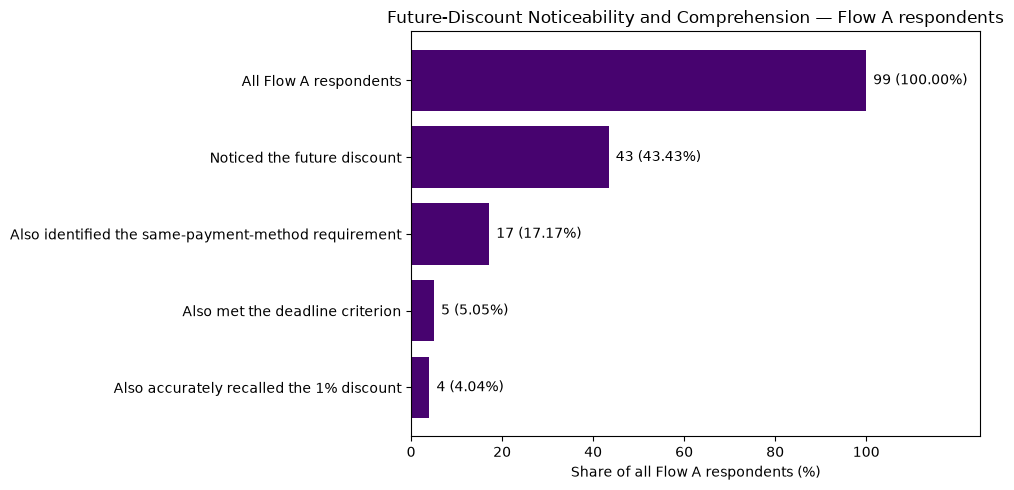

In [49]:
#visualise the numbers among Flow A respondents
fig, ax = plt.subplots (figsize = (10,5))

ax.barh (
    comprehension_coverage['Group'],
    comprehension_coverage['% of all Flow A (n=99)'],
    color = '#47036F'
)

ax.invert_yaxis()

ax.set_title('Future-Discount Noticeability and Comprehension — Flow A respondents')
ax.set_xlabel('Share of all Flow A respondents (%)')
ax.set_ylabel('')

ax.bar_label(
    ax.containers[0],
    labels=[
        f'{count} ({pct:.2f}%)'
        for count, pct in zip(
            comprehension_coverage['Respondents'],
            comprehension_coverage['% of all Flow A (n=99)']
        )
    ],
    padding=5
)

ax.set_xlim(0, 125)
ax.set_xticks([0, 20, 40, 60, 80, 100])

plt.tight_layout()
plt.show()

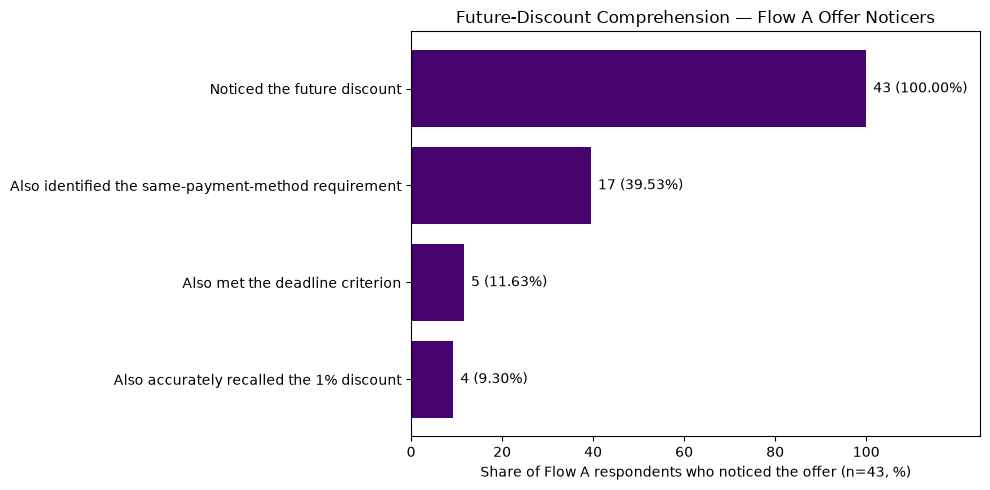

In [50]:
#visualise the numbers among Flow A respondents who noticed the future discount
fig, ax = plt.subplots (figsize = (10,5))

ax.barh (
    comprehension_coverage_noticed['Group'],
    comprehension_coverage_noticed['% of those who noticed the offer (n=43)'],
    color = '#47036F'
)

ax.invert_yaxis()

ax.set_title('Future-Discount Comprehension — Flow A Offer Noticers')
ax.set_xlabel('Share of Flow A respondents who noticed the offer (n=43, %)')
ax.set_ylabel('')

ax.bar_label(
    ax.containers[0],
    labels=[
        f'{count} ({pct:.2f}%)'
        for count, pct in zip(
            comprehension_coverage_noticed['Respondents'],
            comprehension_coverage_noticed['% of those who noticed the offer (n=43)']
        )
    ],
    padding=5
)

ax.set_xlim(0, 125)
ax.set_xticks([0, 20, 40, 60, 80, 100])

plt.tight_layout()
plt.show()

Across all 99 Flow A respondents, 43 (43.43%) noticed the future discount, but only 5 (5.05%) also met both the payment-method and deadline comprehension criteria. Only 4 (4.04%) additionally recalled the discount amount correctly.

The coverage analysis shows that the communication gap extends beyond noticeability: only a small share of all Flow A respondents both noticed the offer and demonstrated understanding of its redemption requirements.

**Future-Discount Comprehension: Conclusion**

**Findings**  

Among the 43 Flow A respondents who noticed the future discount:  
- 17 respondents (39.53%) identified the requirement to reuse the same payment method. The website interpretation was about as common as the correct answer.
- 10 respondents (23.26%) recognised the time limit and reported a deadline within 7 days. More respondents—15 (34.88%)—believed that the discount would apply to any future payments.
- 18 respondents (41.86%) accurately recalled the discount as 1%. The remaining respondents either reported a higher amount or gave responses that did not specify an interpretable discount amount.
- Only 5 respondents (11.63%) met both the payment-method and deadline comprehension criteria. Only 4 (9.30%) met all three criteria, including accurate recall of the discount amount.

Of all 99 Flow A respondents:
- 43 (43.43%) noticed the future discount.
- 17 (17.17%) noticed the offer and identified the same-payment-method requirement.
- 5 (5.05%) also met the deadline criterion.
- 4 (4.04%) also accurately recalled the 1% discount.

**Interpretation**  
Within Flow A, noticing the future discount did not consistently translate into understanding how to qualify for it. The communication gap therefore extends beyond noticeability to understanding the redemption requirements.  

These findings suggest a risk that users may notice the incentive but fail to qualify for it by choosing a different payment method or making their next payment after the deadline. Inflated expectations could also lead to disappointment or reduced trust when the actual discount is received.

**Implications**  
- Name the payment method and explicitly state that the next payment must use the same method to qualify.
- Clearly state the 7-day deadline. Consider showing the exact expiry date on the final screen.
- Make the 1% discount clearly visible and repeat it alongside the redemption requirements.

### 6. Offer Appeal

**Objective**   
Assess whether respondents said they would act on the offer.

**Analysis Sample**   
- All 197 respondents across both flows. This section assesses stated willingness to act on the offer rather than comprehension within Flow A. The survey restated the offer terms before Q28 (intent_to_switch) and Q30 (willingness_to_deposit_7d), so respondents could answer even if they had not noticed the offer in the prototype.
- All 197 also answered Q32 (historical_promo_usage), which provides context from their past experience. In Section 6.3, I restrict the paired comparison to the 164 respondents who had previously received a limited-time offer, using this same subgroup for both measures.

**Methodological Note**  
Q25 contained an error in the numerical example, not in the stated offer terms. It showed €56.40 due on a €60 payment instead of €59.40. This amounts to a 6% discount, six times the stated 1%.
The example came after all the noticeability and comprehension questions analysed in Sections 3–5 (Q14–Q22), so it could not have affected those answers. Q28 and Q30 referred to the 1% discount without repeating the euro example. I use these questions to assess stated willingness to act, but the earlier example may have led respondents to expect greater savings in euros.

**Product Interpretation (a fortiori)**  
If the example made the offer seem more generous and respondents still showed limited willingness to act, that strengthens the concern that the stated 1% discount may not be enough to motivate them. It does not tell us how they would have answered if the example had shown the correct amount.  

**Analysis Plan:**   
6.1. Willingness to Switch Payment Methods (intent_to_switch)  
6.2. Willingness to Deposit Again Within 7 Days (willingness_to_deposit_7d)  
6.3. Reported Response to a Previous Limited-Time Offer (historical_promo_usage)  

#### 6.1. Willingness to Switch Payment Methods (intent_to_switch)

**Objective**  
Assess willingness to make the next deposit using the payment method linked to the discount instead of the usual method  

**Steps:**
- Report response counts and percentages
- Visualise the response distribution
- Calculate the combined shares of positive responses (Top-2) and negative responses (Bottom-2)
- Compare overall willingness to switch with definite willingness

In [51]:
#Count non-missing responses to Q28 (intent_to_switch). Should be 197
intent_to_switch_denominator = df_extracted.intent_to_switch.count()
print(intent_to_switch_denominator)

197


In [52]:
#print unique answers to set the order
print(df_extracted.intent_to_switch.unique())

<StringArray>
[  'Probably yes, I would consider using this payment method',
      'Definitely yes, I would switch to this payment method',
 'Probably no, I would likely prefer my usual payment method',
                                           'It's hard to say',
    'Definitely no, I would stick to my usual payment method']
Length: 5, dtype: str


In [53]:
#set the order
intent_to_switch_order = [
    'Definitely yes, I would switch to this payment method',
    'Probably yes, I would consider using this payment method',
    'Probably no, I would likely prefer my usual payment method',
    'Definitely no, I would stick to my usual payment method',
    "It's hard to say",
]

# calculate counts and percentages
intent_to_switch_counts = df_extracted.intent_to_switch.value_counts()
intent_to_switch_pct = intent_to_switch_counts.div(intent_to_switch_denominator).mul(100)

intent_to_switch_counts_pct = pd.DataFrame ({'Counts': intent_to_switch_counts, 'Percentages': intent_to_switch_pct}).loc[intent_to_switch_order]

display(intent_to_switch_counts_pct.round(2))

,Counts,Percentages
intent_to_switch,,
"Definitely yes, I would switch to this payment method",57,28.93
"Probably yes, I would consider using this payment method",91,46.19
"Probably no, I would likely prefer my usual payment method",28,14.21
"Definitely no, I would stick to my usual payment method",9,4.57
It's hard to say,12,6.09


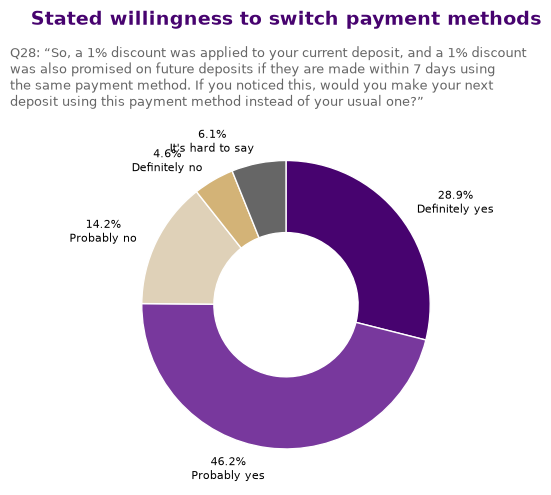

In [54]:
#visualise the distribution

#set short labels
intent_to_switch_labels = [
    'Definitely yes',
    'Probably yes',
    'Probably no',
    'Definitely no',
    "It's hard to say",
]

#set colors
intent_to_switch_colors = [
    "#47036F",
    "#78389D",
    "#DFD1B8",
    "#D3B377",
    "#666666",
]

#start visualising
intent_to_switch_fig, intent_to_switch_ax = plt.subplots(figsize=(6, 5))

# take the percentages in the same response order
intent_to_switch_plot_pct = intent_to_switch_pct.loc[intent_to_switch_order]

# Build one two-line label per slice: percentage above, response label below.
intent_to_switch_outside_labels = [
    f"{pct:.1f}%\n{label}" if pct > 0 else ""
    for pct, label in zip(intent_to_switch_plot_pct, intent_to_switch_labels)
]

# Draw the donut chart with labels outside the ring.
intent_to_switch_ax.pie(
    intent_to_switch_plot_pct,           # Use the percentages to size the slices.
    labels=intent_to_switch_outside_labels,  # Add the two-line label for each slice.
    colors=intent_to_switch_colors,      # Apply the colors in the same order.
    startangle=90,                      # Start the first slice at 12 o'clock.
    counterclock=False,                 # Draw the slices clockwise.
    labeldistance=1.15,                 # Place labels at 1.15 times the outer radius.
    wedgeprops={
        "width": 0.5,                  # Set the ring thickness to 50% of the outer radius.
        "edgecolor": "white",           # Draw white borders between slices.
    },
    textprops={
        "fontsize": 8,                  # Set the label font size to 8 points.
        "multialignment": "center",     # Center the two lines relative to each other.
    },
)

# Add a title
intent_to_switch_fig.suptitle(
    "Stated willingness to switch payment methods",
    ha="center",
    fontsize=14,
    fontweight="bold",
    color="#47036F",
)

# place the original survey question below the title.
intent_to_switch_fig.text(
    0.04, 0.91,
    "Q28: “So, a 1% discount was applied to your current deposit, and a 1% discount\n"
    "was also promised on future deposits if they are made within 7 days using\n"
    "the same payment method. If you noticed this, would you make your next\n"
    "deposit using this payment method instead of your usual one?”",
    ha="left",
    va="top",
    fontsize=9,
    color="#666666",
    linespacing=1.3,
)

# keep the chart and its outside labels below the question.
intent_to_switch_fig.tight_layout(rect=(0, 0, 1, 0.85))

plt.show()

In [55]:
# calculate top-2 and bottom-2
intent_to_switch_top2 = [
    'Probably yes, I would consider using this payment method',
    'Definitely yes, I would switch to this payment method'
    ]
intent_to_switch_bottom2 = [
    'Probably no, I would likely prefer my usual payment method',
    'Definitely no, I would stick to my usual payment method'
    ]

intent_to_switch_counts_pct.loc['Top-2 (Probably + Definitely yes )'] = (intent_to_switch_counts_pct.loc[intent_to_switch_top2].sum())
intent_to_switch_counts_pct.loc['Bottom-2 (Probably + Definitely no )'] = (intent_to_switch_counts_pct.loc[intent_to_switch_bottom2].sum())
display(intent_to_switch_counts_pct.round(2))

,Counts,Percentages
intent_to_switch,,
"Definitely yes, I would switch to this payment method",57.0,28.93
"Probably yes, I would consider using this payment method",91.0,46.19
"Probably no, I would likely prefer my usual payment method",28.0,14.21
"Definitely no, I would stick to my usual payment method",9.0,4.57
It's hard to say,12.0,6.09
Top-2 (Probably + Definitely yes ),148.0,75.13
Bottom-2 (Probably + Definitely no ),37.0,18.78


The offer was enough for most respondents to consider switching, but only a minority expressed firm intent:
- A majority (75.13%) are open to considering the switch, suggesting that the offer as presented is enough to attract initial interest.
- However, fewer than three in ten respondents (28.93%) said they would definitely switch. The remaining 71.07% did not express firm intent, although many would consider switching. One possible explanation is that the 1% discount may not offer enough savings to create firm intent. 

_Note: The actual switching rate with a correctly presented 1% discount may be even lower than the 28.93% who said they would definitely switch. The example in Q25 overstated the savings and may have made the offer seem more attractive. In addition, Q28 measured stated intent: respondents said what they would do on their next deposit, which may not match what they actually do._

#### 6.2. Willingness to Deposit Again Within 7 Days (willingness_to_deposit_7d)

**Objective**  
Assess whether respondents said they would make a special effort to make their next deposit within 7 days to receive the 1% discount.  

**Steps:**
- Report response counts and percentages
- Visualise the response distribution
- Identify the share willing to make a special effort to deposit within 7 days

In [56]:
#Count non-missing responses to Q30 (willingness_to_deposit_7d). Should be 197
willingness_to_deposit_7d_denominator = df_extracted.willingness_to_deposit_7d.count()
print(willingness_to_deposit_7d_denominator)

197


In [57]:
#print unique answers to set the order
print(df_extracted.willingness_to_deposit_7d.unique())

<StringArray>
['No', 'It’s hard to say', 'Yes', 'It's hard to say']
Length: 4, dtype: str


In [58]:
#standardize the apostrophe in the Q30 response label
df_extracted['willingness_to_deposit_7d'] = df_extracted['willingness_to_deposit_7d'].replace("It’s hard to say","It's hard to say")

print(df_extracted.willingness_to_deposit_7d.unique())

<StringArray>
['No', 'It's hard to say', 'Yes']
Length: 3, dtype: str


In [59]:
#set the order
willingness_to_deposit_7d_order = ["Yes", 
                                   "No",
                                   "It's hard to say"]

# calculate counts and percentages
willingness_to_deposit_7d_counts = df_extracted['willingness_to_deposit_7d'].value_counts()
willingness_to_deposit_7d_pct = willingness_to_deposit_7d_counts.div(willingness_to_deposit_7d_denominator).mul(100)

willingness_to_deposit_7d_counts_pct = pd.DataFrame({'Counts': willingness_to_deposit_7d_counts,
                                                      'Percentages':willingness_to_deposit_7d_pct}).loc[willingness_to_deposit_7d_order]

display(willingness_to_deposit_7d_counts_pct.round(2))

,Counts,Percentages
willingness_to_deposit_7d,,
Yes,102,51.78
No,58,29.44
It's hard to say,37,18.78


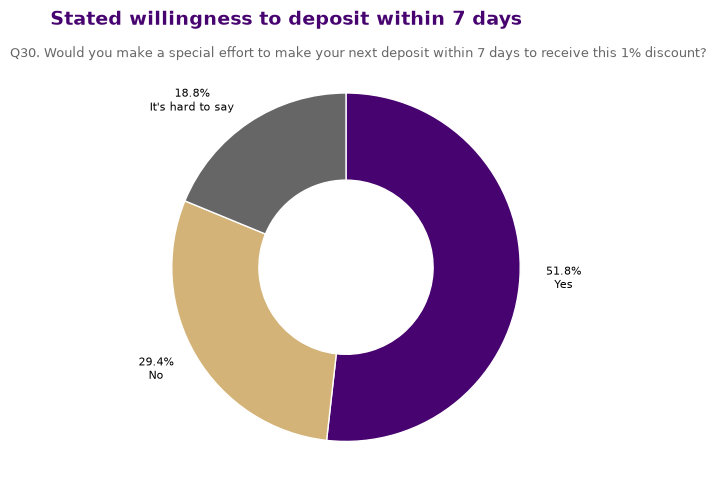

In [60]:
#visualise the distribution

#set colors
willingness_to_deposit_7d_colors = [
    "#47036F",
    "#D3B377",
    "#666666",
]

#start visualising
willingness_to_deposit_7d_fig, willingness_to_deposit_7d_ax = plt.subplots(figsize=(6, 5))

# take the percentages in the same response order
willingness_to_deposit_7d_plot_pct = willingness_to_deposit_7d_pct.loc[willingness_to_deposit_7d_order]

# Build one two-line label per slice: percentage above, response label below.
willingness_to_deposit_7d_outside_labels = [
    f"{pct:.1f}%\n{label}" if pct > 0 else ""
    for pct, label in zip(willingness_to_deposit_7d_plot_pct, willingness_to_deposit_7d_order)
]

# Draw the donut chart with labels outside the ring.
willingness_to_deposit_7d_ax.pie(
    willingness_to_deposit_7d_plot_pct,           # Use the percentages to size the slices.
    labels=willingness_to_deposit_7d_outside_labels,  # Add the two-line label for each slice.
    colors=willingness_to_deposit_7d_colors,      # Apply the colors in the same order.
    startangle=90,                      # Start the first slice at 12 o'clock.
    counterclock=False,                 # Draw the slices clockwise.
    labeldistance=1.15,                 # Place labels at 1.15 times the outer radius.
    wedgeprops={
        "width": 0.5,                  # Set the ring thickness to 50% of the outer radius.
        "edgecolor": "white",           # Draw white borders between slices.
    },
    textprops={
        "fontsize": 8,                  # Set the label font size to 8 points.
        "multialignment": "center",     # Center the two lines relative to each other.
    },
)

# Add a title
willingness_to_deposit_7d_fig.suptitle(
    "Stated willingness to deposit within 7 days",
    ha="center",
    fontsize=14,
    fontweight="bold",
    color="#47036F",
)

# place the original survey question below the title.
willingness_to_deposit_7d_fig.text(
    0.04, 0.91,
    "Q30. Would you make a special effort to make your next deposit within 7 days to receive this 1% discount?",
    ha="left",
    va="top",
    fontsize=9,
    color="#666666",
    linespacing=1.3,
)

# keep the chart and its outside labels below the question.
willingness_to_deposit_7d_fig.tight_layout(rect=(0.2, 0, 1, 1))

plt.show()

Just over half of respondents (51.78%) said they would make a special effort to make their next deposit within 7 days for the stated 1% discount. 
To put it in context, the next section looks at whether respondents reported acting in time to claim a previous limited-time offer.

#### 6.3. Reported Response to a Previous Limited-Time Offer (historical_promo_usage)

**Objective**  
Use respondents’ reported response to their most recent limited-time bonus or discount as a contextual benchmark for stated willingness to deposit within 7 days to receive our offer.

**Steps:**
- Report response counts and percentages for all respondents
- Report response counts and percentages among respondents who had previously received a limited-time bonus or discount offer
- Within this experienced subgroup, compare the share willing to act within 7 days for our offer with the share who reported acting in time on their previous offer (two-sided exact McNemar test)

In [61]:
#Count non-missing responses to Q32 (historical_promo_usage). Should be 197
historical_promo_usage_denominator = df_extracted.historical_promo_usage.count()
print(historical_promo_usage_denominator)

197


In [62]:
#print unique answers to set the order
print(df_extracted.historical_promo_usage.unique())

<StringArray>
[                         'No, I didn’t do it in time',
 'I’ve never been offered this kind of bonus/discount',
     'Yes, I did it in time to get the bonus/discount']
Length: 3, dtype: str


In [63]:
#set the order
historical_promo_usage_order = ["Yes, I did it in time to get the bonus/discount", 
                                "No, I didn’t do it in time",
                                "I’ve never been offered this kind of bonus/discount"]

# calculate counts and percentages
historical_promo_usage_counts = df_extracted['historical_promo_usage'].value_counts()
historical_promo_usage_pct = (historical_promo_usage_counts.div(historical_promo_usage_denominator).mul(100))

historical_promo_usage_counts_pct = pd.DataFrame({'Counts': historical_promo_usage_counts,
                                                  'Percentages':historical_promo_usage_pct}).loc[historical_promo_usage_order]

display(historical_promo_usage_counts_pct.round(2))

,Counts,Percentages
historical_promo_usage,,
"Yes, I did it in time to get the bonus/discount",110,55.84
"No, I didn’t do it in time",54,27.41
I’ve never been offered this kind of bonus/discount,33,16.75


Next, I examine the share who reported acting in time to claim their previous bonus or discount, excluding respondents who had never received such an offer.  This provides a past-behavior benchmark for assessing stated willingness to act within 7 days for our offer. 
For the paired comparison, I will calculate both shares using this same subgroup.

In [64]:
# Summarize past offer use among respondents who had received such an offer.
historical_promo_usage_experienced_order = [
    "Yes, I did it in time to get the bonus/discount",
    "No, I didn’t do it in time",
]

historical_promo_usage_experienced_counts = historical_promo_usage_counts.loc[historical_promo_usage_experienced_order]

historical_promo_usage_experienced_pct = (
    historical_promo_usage_experienced_counts
    .div(historical_promo_usage_experienced_counts.sum())
    .mul(100)
)

historical_promo_usage_experienced_summary = pd.DataFrame({
    "Counts": historical_promo_usage_experienced_counts,
    "Percentages": historical_promo_usage_experienced_pct,
})

display(historical_promo_usage_experienced_summary.round(2))

,Counts,Percentages
historical_promo_usage,,
"Yes, I did it in time to get the bonus/discount",110,67.07
"No, I didn’t do it in time",54,32.93


Among respondents who had previously received a limited-time offer, 67.07% reported acting in time to claim it. I use this share as a contextual benchmark for stated willingness to deposit within 7 days for our offer.

For a like-for-like comparison, I restrict both measures to this same subgroup. I then use a two-sided McNemar test to assess whether the two paired proportions of positive responses differ.

Respondents who had never received such an offer are excluded from this comparison because they had no opportunity to demonstrate the past behavior used as the benchmark.

In [65]:
# create subsample of respondents who had previously received a limited-time offer
promo_usage_experienced_subsample = df_extracted.loc[
    df_extracted['historical_promo_usage'].isin(historical_promo_usage_experienced_order), #select rows
    ['willingness_to_deposit_7d', "historical_promo_usage"] #select columns
]

# group "No" and "It's hard to say" to compare positive vs. non-positive responses.
promo_usage_experienced_subsample["willingness_to_deposit_7d"] = (promo_usage_experienced_subsample["willingness_to_deposit_7d"]
                                                                .replace(["It's hard to say", "No"], "It's hard to say + No"))

#check the result
print(f'historical_promo_usage unique answers {promo_usage_experienced_subsample.historical_promo_usage.unique()}\n')
print(f'willingness_to_deposit_7d unique answers {promo_usage_experienced_subsample.willingness_to_deposit_7d.unique()}')

historical_promo_usage unique answers <StringArray>
['No, I didn’t do it in time', 'Yes, I did it in time to get the bonus/discount']
Length: 2, dtype: str

willingness_to_deposit_7d unique answers <StringArray>
['It's hard to say + No', 'Yes']
Length: 2, dtype: str


In [66]:
# Cross-tabulate stated willingness for our offer and self-reported past offer use to see the distribution across pairs of answers
offer_response_counts = pd.crosstab(
    promo_usage_experienced_subsample["willingness_to_deposit_7d"],
    promo_usage_experienced_subsample["historical_promo_usage"],
    margins=True,
)

offer_response_pct = offer_response_counts.div(offer_response_counts.loc['All','All']).mul(100)

display(offer_response_counts)
display(offer_response_pct.round(2))

historical_promo_usage,"No, I didn’t do it in time","Yes, I did it in time to get the bonus/discount",All
willingness_to_deposit_7d,,,
It's hard to say + No,37,34,71
Yes,17,76,93
All,54,110,164


historical_promo_usage,"No, I didn’t do it in time","Yes, I did it in time to get the bonus/discount",All
willingness_to_deposit_7d,,,
It's hard to say + No,22.56,20.73,43.29
Yes,10.37,46.34,56.71
All,32.93,67.07,100.00


Within the experienced subgroup (n = 164), 56.71% stated that they would make a special effort to deposit within 7 days for our offer, compared with 67.07% who reported acting in time to claim their previous offer. The observed difference is -10.37 percentage points (our offer - past experience).

The paired responses show the following pattern:
- 76 respondents (46.34%) reported acting in time on their previous offer and expressed willingness to act on ours
- 37 respondents (22.56%) reported not acting in time on their previous offer and answered either "No" or "It's hard to say" about ours
- 34 respondents (20.73%) reported acting in time on their previous offer but answered either "No" or "It's hard to say" about ours
- 17 respondents (10.37%) reported not acting in time on their previous offer but expressed willingness to act on ours

Among respondents who reported acting in time on their previous offer, 34 did not express willingness to act on ours. In contrast, 17 respondents who had not acted in time on their previous offer expressed willingness to act on ours.

This pattern suggests that our offer may be less motivating than the past-experience benchmark. I next test whether the difference in positive response rates is statistically significant.


I use a two-sided exact McNemar test at a significance level of 0.05 to assess whether the paired proportions of positive responses differ.

- H0: Within the experienced subgroup, the proportion expressing willingness to act on our offer equals the proportion reporting that they acted in time on their previous offer.
- H1: Within the experienced subgroup, these two proportions differ.

This comparison provides context for offer appeal (it compares stated intention with self-reported past behavior)

In [67]:
#remove totals to retain the 2x2 table
offer_response_mcnemar_counts = offer_response_counts.drop(index = 'All', columns = 'All')
offer_response_mcnemar_counts

#run a two-sided exact McNemar test
offer_response_mcnemar_result = mcnemar(offer_response_mcnemar_counts.to_numpy(), exact=True)

display(offer_response_mcnemar_counts)
print(offer_response_mcnemar_result)

historical_promo_usage,"No, I didn’t do it in time","Yes, I did it in time to get the bonus/discount"
willingness_to_deposit_7d,,
It's hard to say + No,37,34
Yes,17,76


pvalue      0.024092907698449295
statistic   17.0


Among respondents who had received a limited-time offer before (n = 164):
- 56.71% said they would act within 7 days for our offer
- 67.07% said they had acted in time on their previous offer  
The positive response rate for our offer was 10.37 percentage points lower.

The two-sided exact McNemar test returned p = 0.0241, below the significance level of 0.05. I therefore reject the null hypothesis that the two positive response rates are equal.

Our offer appears less motivating than the past-experience benchmark. However, this comparison is between stated intention and self-reported past behavior, and the previous offers may have had different rewards and conditions.

Two factors may make the responses to our offer overly optimistic:
- First, stated willingness may not translate into action
- Second, the incorrect monetary example shown earlier implied a 6% discount rather than the intended 1%, which may have made the offer seem more generous

**Even with these potentially favorable influences, willingness to act remained below the benchmark. This raises concerns about whether a correctly presented 1% discount would provide enough motivation.**

**Offer Appeal: Conclusion**

**Findings**

Across all 197 respondents:

- 75.13% said they would probably or definitely switch to the payment method linked to the discount. However, only 28.93% said they would definitely switch.
- 51.78% said they would make a special effort to make their next deposit within 7 days to receive the stated 1% discount.

To put stated willingness into context, I use respondents' reported response to a previous limited-time offer as a benchmark. Both measures are compared within the same subgroup of respondents who had previously received such an offer (n = 164).

In this subgroup, 56.71% expressed willingness to act within 7 days for our offer, compared with 67.07% who reported acting in time on their previous offer. The difference was −10.37 pp (our offer − past experience. Two-sided exact McNemar test, p = 0.0241).

**Interpretation**

The offer attracted broad stated interest in switching payment methods, but firm intent was less common. Willingness to make a special effort to deposit within 7 days was also far from universal.

Within the experienced subgroup, the lower positive response rate raises concerns about the offer's ability to motivate timely repeat use. The past-experience benchmark provides useful context: 34 of the 110 respondents who reported acting in time on their previous offer did not express willingness to act on ours. Our offer therefore did not elicit positive stated intent from some respondents who had previously acted on a time-limited incentive.*  
_* This comparison is useful for contextualising offer appeal. It compares stated intention with self-reported past behavior, and previous offers may have had different rewards and conditions._

Two factors may make the responses to our offer overly optimistic:
- First, stated willingness may not translate into actual behavior
- Second, the incorrect monetary example in Q25 implied a 6% discount rather than the stated 1%, which may have made the offer seem more generous

Even with these potentially favorable influences, willingness to act remained below the past-experience benchmark. This strengthens the concern that a correctly presented 1% discount may provide limited motivation. 

**Implications**

Improving noticeability and comprehension alone may not be enough to drive repeat payments. The motivational value of the correctly presented 1% offer still needs to be validated.
The production experiment should measure actual payment-method reuse and repeat payments within 7 days, rather than treating stated willingness as evidence of behavioral uplift.

### 7. Conclusion

**Findings**

Flow A (no button) performed better at making the future discount noticeable.  
In Flow A, 43.43% of respondents reported noticing it, compared with 23.47% in Flow B (with button). The difference of 19.96 pp was statistically significant (95% CI: 6.79 to 32.20 pp; p = 0.003). The groups differed somewhat in age and gender, but accounting for these differences did not materially change Flow A's advantage.

The current-discount comparison was inconclusive. The results therefore support choosing Flow A for communicating the future offer, but do not show that it performs better on every measure.

Two problems remain:

- Understanding the conditions. Of the 43 Flow A respondents who noticed the future discount, only 5 (11.63%) met both the payment-method and deadline comprehension criteria. They represented 5.05% of all 99 Flow A respondents.
- Willingness to act. Across both flows, 75.13% said they would probably or definitely switch payment methods, but only 28.93% said they would definitely switch. Among respondents who had received a limited-time offer before, 56.71% said they would act within 7 days for our offer, compared with 67.07% who reported acting in time on their previous offer.

**Interpretation**

Users need to notice the offer, see enough value in it and understand its conditions to act on it.

Flow A did better on noticeability, but noticing the offer did not consistently mean understanding how to get the discount. The offer also attracted more interest than firm commitment.

The comparison with past offers also raises concerns about motivation. Some respondents who reported acting in time on a previous offer did not express willingness to act on ours. This suggests that our offer may not be compelling enough even for some users who have acted on time-limited incentives before.

Stated willingness may overestimate actual action, and the incorrect example in Q25 may have made the discount seem larger. Even with these potentially favorable influences, willingness to act was below the past-experience benchmark.

The results did not support the initial idea that the “Accept and close” button would help users notice the future discount.  
- One possible explanation is that the message's position made it look like a cookie banner, prompting users to close it without reading.  
- Closing the message also removed the reminder from the final payment confirmation screen.  
The study cannot separate the possible effect of habitual dismissal from the effect of losing this reminder.

**Implications**

Use Flow A as the basis for the next version, but improve how it explains the offer:

- Name the payment method and clearly state that the next payment must use the same method.
- Make the 7-day deadline easy to see. Consider showing the exact expiry date.
- Show the 1% discount alongside these conditions.

Then test the revised version in production. Measure whether it increases use of the same payment method within 7 days, whether it increases repeat payments overall, and how much the discount costs.

The main question is whether the offer leads to enough additional repeat payments to justify its cost.